#  Project Panopticon: Intelligent Exam Proctoring AI

### EduGuard AI — Machine Learning Division

## Objective

Develop a machine learning system that detects suspicious behavior during online examinations while minimizing false accusations against genuine students.

## Dataset Sources

1. Video Telemetry (Eye Gaze + Audio)
2. System Events (Tab Switching + Cheating Labels)

## Project Pipeline

Raw Data
→ Data Validation
→ Temporal Alignment
→ Missing Value Handling
→ Feature Engineering
→ Model Training
→ Probability-Based Decision Making
→ Evaluation
→ Executive Recommendation

In [2]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Notebook appearance
sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (10,6)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# ==========================================
# 2. LOAD DATASETS
# ==========================================

VIDEO_PATH = "../data/video_telemetry (1) (1).csv"
SYSTEM_PATH = "../data/system_events (1) (1).csv"

video_df = pd.read_csv(VIDEO_PATH)
sys_df = pd.read_csv(SYSTEM_PATH)

print("Video Dataset Shape :", video_df.shape)
print("System Dataset Shape:", sys_df.shape)

Video Dataset Shape : (10000, 3)
System Dataset Shape: (167, 3)


## 2. Raw Data Inspection

Before processing the data, we inspect the structure, data types, sample records, and statistical properties of both data sources.

The project contains two asynchronous data sources:

- **Video telemetry:** continuous eye-gaze and audio measurements.
- **System events:** irregular computer interaction events with the cheating label.

# ==========================================
# 2A. RAW DATA INSPECTION
# ==========================================

print("VIDEO TELEMETRY")
print("=" * 50)

display(video_df.head())

print("\nVideo Data Types:")
print(video_df.dtypes)

print("\nVideo Information:")
video_df.info()

In [4]:
print("SYSTEM EVENTS")
print("=" * 50)

display(sys_df.head())

print("\nSystem Event Data Types:")
print(sys_df.dtypes)

print("\nSystem Event Information:")
sys_df.info()

SYSTEM EVENTS


,timestamp,tab_switches,is_cheating
0,2023-12-01 08:00:32.181296,1,0
1,2023-12-01 08:01:01.923778,1,1
2,2023-12-01 08:01:24.462808,1,0
3,2023-12-01 08:04:10.610743,1,0
4,2023-12-01 08:04:23.902814,1,0



System Event Data Types:
timestamp         str
tab_switches    int64
is_cheating     int64
dtype: object

System Event Information:
<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   timestamp     167 non-null    str  
 1   tab_switches  167 non-null    int64
 2   is_cheating   167 non-null    int64
dtypes: int64(2), str(1)
memory usage: 4.0 KB


In [5]:
print("VIDEO TELEMETRY STATISTICS")
display(video_df.describe())

VIDEO TELEMETRY STATISTICS


,eye_gaze_angle,audio_db
count,9268.000000,9268.000000
mean,10.648648,39.492497
std,14.149376,12.109687
min,-2.059864,17.352184
25%,3.919475,32.344491
50%,5.426888,36.156197
75%,7.314337,40.655750
max,61.050591,87.609339


In [6]:
print("SYSTEM EVENT STATISTICS")
display(sys_df.describe())

SYSTEM EVENT STATISTICS


,tab_switches,is_cheating
count,167.000000,167.000000
mean,1.449102,0.461078
std,0.741690,0.499982
min,1.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,0.000000
75%,2.000000,1.000000
max,3.000000,1.000000


## 3. Timestamp Validation

The two datasets record events at different temporal resolutions.

Video telemetry is recorded continuously, while system events occur at irregular timestamps.

We therefore need to convert both timestamp columns into Pandas datetime objects before performing temporal alignment.

In [7]:
# ==========================================
# 3A. CONVERT TIMESTAMPS
# ==========================================

video_df["timestamp"] = pd.to_datetime(video_df["timestamp"])
sys_df["timestamp"] = pd.to_datetime(sys_df["timestamp"])

print("Video timestamp type:", video_df["timestamp"].dtype)
print("System timestamp type:", sys_df["timestamp"].dtype)

Video timestamp type: datetime64[us]
System timestamp type: datetime64[us]


In [8]:
print("VIDEO TIME RANGE")
print("Start:", video_df["timestamp"].min())
print("End  :", video_df["timestamp"].max())

print("\nSYSTEM EVENT TIME RANGE")
print("Start:", sys_df["timestamp"].min())
print("End  :", sys_df["timestamp"].max())

VIDEO TIME RANGE
Start: 2023-12-01 08:00:00
End  : 2023-12-01 10:46:39

SYSTEM EVENT TIME RANGE
Start: 2023-12-01 08:00:32.181296
End  : 2023-12-01 10:45:39.962066


In [9]:
print("Video already sorted:",
      video_df["timestamp"].is_monotonic_increasing)

print("System events already sorted:",
      sys_df["timestamp"].is_monotonic_increasing)

Video already sorted: True
System events already sorted: True


In [10]:
# ==========================================
# 3B. SORT CHRONOLOGICALLY
# ==========================================

video_df = video_df.sort_values("timestamp").reset_index(drop=True)
sys_df = sys_df.sort_values("timestamp").reset_index(drop=True)

print("✅ Both datasets sorted chronologically.")

✅ Both datasets sorted chronologically.


## 4. Data Quality Audit

A machine learning model is only as reliable as the data supplied to it.

Before temporal alignment, we check:

- Missing values
- Duplicate timestamps
- Timestamp coverage
- Invalid target values
- Class distribution

# ==========================================
# 4A. MISSING VALUE AUDIT
# ==========================================

print("VIDEO TELEMETRY - MISSING VALUES")
print("=" * 50)

display(video_df.isna().sum())

print("\nSYSTEM EVENTS - MISSING VALUES")
print("=" * 50)

display(sys_df.isna().sum())

In [11]:
print("Video duplicate timestamps:",
      video_df["timestamp"].duplicated().sum())

print("System event duplicate timestamps:",
      sys_df["timestamp"].duplicated().sum())

Video duplicate timestamps: 0
System event duplicate timestamps: 0


In [12]:
print("Unique values in is_cheating:")
print(sys_df["is_cheating"].unique())

Unique values in is_cheating:
[0 1]


In [13]:
invalid_targets = sys_df[
    ~sys_df["is_cheating"].isin([0, 1])
]

print("Invalid target rows:", len(invalid_targets))

Invalid target rows: 0


In [14]:
# ==========================================
# 4B. CLASS DISTRIBUTION
# ==========================================

class_counts = sys_df["is_cheating"].value_counts().sort_index()

print("Class counts:")
display(class_counts)

class_percent = (
    sys_df["is_cheating"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

print("Class percentages:")
display(class_percent)

Class counts:


is_cheating
0    90
1    77
Name: count, dtype: int64

Class percentages:


is_cheating
0    53.892216
1    46.107784
Name: proportion, dtype: float64

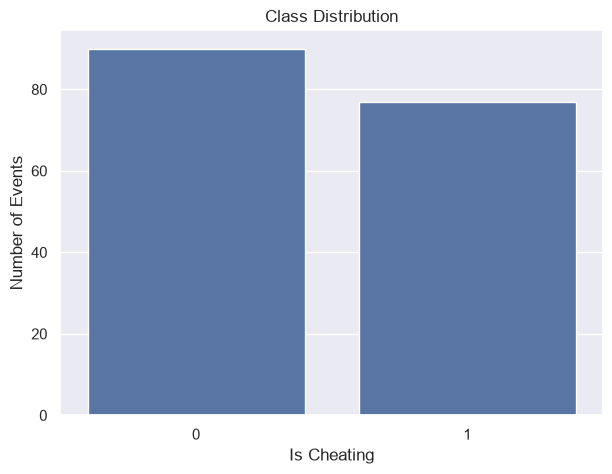

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=sys_df,
    x="is_cheating"
)

plt.title("Class Distribution")
plt.xlabel("Is Cheating")
plt.ylabel("Number of Events")
plt.show()

## 5. Temporal Alignment

The video telemetry is sampled once per second, whereas system events occur at irregular timestamps.

To combine the two sources, system-event observations are aligned to the video timeline using a backward as-of merge.

A backward merge associates each video timestamp with the most recent system event that occurred at or before that timestamp.

In [16]:
# ==========================================
# 5A. PREPARE SYSTEM EVENTS FOR MERGING
# ==========================================

sys_merge = sys_df.copy()

sys_merge = sys_merge.rename(
    columns={
        "timestamp": "event_timestamp"
    }
)

print("System event data prepared for temporal alignment.")

display(sys_merge.head())

System event data prepared for temporal alignment.


,event_timestamp,tab_switches,is_cheating
0,2023-12-01 08:00:32.181296,1,0
1,2023-12-01 08:01:01.923778,1,1
2,2023-12-01 08:01:24.462808,1,0
3,2023-12-01 08:04:10.610743,1,0
4,2023-12-01 08:04:23.902814,1,0


In [17]:
# ==========================================
# 5B. TEMPORAL AS-OF MERGE
# ==========================================

merged_df = pd.merge_asof(
    video_df,
    sys_merge,
    left_on="timestamp",
    right_on="event_timestamp",
    direction="backward"
)

print("Merged dataset shape:", merged_df.shape)

display(merged_df.head(20))

Merged dataset shape: (10000, 6)


,timestamp,eye_gaze_angle,audio_db,event_timestamp,tab_switches,is_cheating
0,2023-12-01 08:00:00,2.560857,36.553781,NaT,NaN,NaN
1,2023-12-01 08:00:01,10.177137,39.102627,NaT,NaN,NaN
2,2023-12-01 08:00:02,5.761714,31.228565,NaT,NaN,NaN
3,2023-12-01 08:00:03,9.787105,34.051405,NaT,NaN,NaN
4,2023-12-01 08:00:04,4.572665,35.245018,NaT,NaN,NaN
5,2023-12-01 08:00:05,7.471741,43.685711,NaT,NaN,NaN
6,2023-12-01 08:00:06,7.148505,32.754163,NaT,NaN,NaN
7,2023-12-01 08:00:07,9.192380,43.786308,NaT,NaN,NaN
8,2023-12-01 08:00:08,4.223888,34.097144,NaT,NaN,NaN
9,2023-12-01 08:00:09,3.524030,39.177137,NaT,NaN,NaN


In [18]:
# ==========================================
# 5C. TEMPORAL ALIGNMENT AUDIT
# ==========================================

merged_df["event_time_difference"] = (
    merged_df["timestamp"]
    - merged_df["event_timestamp"]
).dt.total_seconds()

display(
    merged_df[
        [
            "timestamp",
            "event_timestamp",
            "event_time_difference",
            "tab_switches",
            "is_cheating"
        ]
    ].head(50)
)

,timestamp,event_timestamp,event_time_difference,tab_switches,is_cheating
0,2023-12-01 08:00:00,NaT,NaN,NaN,NaN
1,2023-12-01 08:00:01,NaT,NaN,NaN,NaN
2,2023-12-01 08:00:02,NaT,NaN,NaN,NaN
3,2023-12-01 08:00:03,NaT,NaN,NaN,NaN
4,2023-12-01 08:00:04,NaT,NaN,NaN,NaN
5,2023-12-01 08:00:05,NaT,NaN,NaN,NaN
6,2023-12-01 08:00:06,NaT,NaN,NaN,NaN
7,2023-12-01 08:00:07,NaT,NaN,NaN,NaN
8,2023-12-01 08:00:08,NaT,NaN,NaN,NaN
9,2023-12-01 08:00:09,NaT,NaN,NaN,NaN


In [19]:
print("Temporal alignment statistics:")
display(
    merged_df["event_time_difference"].describe()
)

Temporal alignment statistics:


count    9967.000000
mean       77.439561
std        75.621839
min         0.007706
25%        19.480299
50%        51.365854
75%       114.463571
max       421.518427
Name: event_time_difference, dtype: float64

In [20]:
print("Rows without a previous system event:")

print(
    merged_df["event_timestamp"].isna().sum()
)

Rows without a previous system event:
33


In [21]:
print("Rows with a matched system event:")

print(
    merged_df["event_timestamp"].notna().sum()
)

Rows with a matched system event:
9967


In [22]:
print("Merged DataFrame columns:")
print(merged_df.columns.tolist())

Merged DataFrame columns:
['timestamp', 'eye_gaze_angle', 'audio_db', 'event_timestamp', 'tab_switches', 'is_cheating', 'event_time_difference']


In [23]:
merged_df["event_time_difference"] = (
    merged_df["timestamp"] - merged_df["event_timestamp"]
).dt.total_seconds()

In [24]:
first_event = sys_df["timestamp"].iloc[0]

print("First system event:", first_event)

display(
    merged_df[
        (
            merged_df["timestamp"] >= first_event - pd.Timedelta(seconds=5)
        )
        &
        (
            merged_df["timestamp"] <= first_event + pd.Timedelta(seconds=10)
        )
    ][
        [
            "timestamp",
            "event_timestamp",
            "event_time_difference",
            "tab_switches",
            "is_cheating"
        ]
    ]
)

First system event: 2023-12-01 08:00:32.181296


,timestamp,event_timestamp,event_time_difference,tab_switches,is_cheating
28,2023-12-01 08:00:28,NaT,NaN,NaN,NaN
29,2023-12-01 08:00:29,NaT,NaN,NaN,NaN
30,2023-12-01 08:00:30,NaT,NaN,NaN,NaN
31,2023-12-01 08:00:31,NaT,NaN,NaN,NaN
32,2023-12-01 08:00:32,NaT,NaN,NaN,NaN
33,2023-12-01 08:00:33,2023-12-01 08:00:32.181296,0.818704,1.0,0.0
34,2023-12-01 08:00:34,2023-12-01 08:00:32.181296,1.818704,1.0,0.0
35,2023-12-01 08:00:35,2023-12-01 08:00:32.181296,2.818704,1.0,0.0
36,2023-12-01 08:00:36,2023-12-01 08:00:32.181296,3.818704,1.0,0.0
37,2023-12-01 08:00:37,2023-12-01 08:00:32.181296,4.818704,1.0,0.0


## 6. Missing Value Treatment

Missing values are handled according to the meaning of each variable.

Video telemetry contains missing sensor observations in `eye_gaze_angle` and `audio_db`. Since these are continuous time-series measurements, temporal interpolation can be used when valid observations exist before and after a missing observation.

System-event missingness is handled separately because the initial unmatched rows occur before the first recorded system event.

In [25]:
# ==========================================
# 6A. SENSOR MISSING VALUE AUDIT
# ==========================================

sensor_columns = [
    "eye_gaze_angle",
    "audio_db"
]

print("Missing sensor values BEFORE interpolation")
print("=" * 50)

display(merged_df[sensor_columns].isna().sum())

print("\nMissing percentage:")
display(
    merged_df[sensor_columns].isna().mean().mul(100).round(2)
)

Missing sensor values BEFORE interpolation


eye_gaze_angle    732
audio_db          732
dtype: int64


Missing percentage:


eye_gaze_angle    7.32
audio_db          7.32
dtype: float64

In [26]:
# ============================================================
# 6B. SENSOR TEMPORAL INTERPOLATION
# ============================================================

merged_df[sensor_columns] = (
    merged_df[sensor_columns]
    .interpolate(method="linear")
)

print("Missing sensor values AFTER interpolation")
print("=" * 50)

display(merged_df[sensor_columns].isna().sum())

Missing sensor values AFTER interpolation


eye_gaze_angle    0
audio_db          0
dtype: int64

In [27]:
print("Remaining missing percentage:")
display(
    merged_df[sensor_columns]
    .isna()
    .mean()
    .mul(100)
    .round(2)
)

Remaining missing percentage:


eye_gaze_angle    0.0
audio_db          0.0
dtype: float64

In [27]:
# ============================================================
# 6C. SYSTEM-EVENT MISSINGNESS HANDLING
# ============================================================

print("System-event missing values BEFORE handling")
print("=" * 50)

display(
    merged_df[
        ["event_timestamp", "tab_switches", "is_cheating"]
    ].isna().sum()
)

System-event missing values BEFORE handling


event_timestamp    33
tab_switches       33
is_cheating        33
dtype: int64

In [28]:
unmatched_rows = merged_df["event_timestamp"].isna()

print("Unmatched video rows:", unmatched_rows.sum())
print("Matched video rows:", (~unmatched_rows).sum())
print("Total rows:", len(merged_df))

Unmatched video rows: 33
Matched video rows: 9967
Total rows: 10000


In [29]:
# Check the unmatched rows
print("UNMATCHED SYSTEM-EVENT ROWS")
print("=" * 50)

display(
    merged_df.loc[
        unmatched_rows,
        ["timestamp", "eye_gaze_angle", "audio_db"]
    ]
)

UNMATCHED SYSTEM-EVENT ROWS


,timestamp,eye_gaze_angle,audio_db
0,2023-12-01 08:00:00,2.560857,36.553781
1,2023-12-01 08:00:01,10.177137,39.102627
2,2023-12-01 08:00:02,5.761714,31.228565
3,2023-12-01 08:00:03,9.787105,34.051405
4,2023-12-01 08:00:04,4.572665,35.245018
5,2023-12-01 08:00:05,7.471741,43.685711
6,2023-12-01 08:00:06,7.148505,32.754163
7,2023-12-01 08:00:07,9.192380,43.786308
8,2023-12-01 08:00:08,4.223888,34.097144
9,2023-12-01 08:00:09,3.524030,39.177137


In [30]:
print("Unmatched timestamp range:")
print(
    "Start:", merged_df.loc[unmatched_rows, "timestamp"].min()
)
print(
    "End:", merged_df.loc[unmatched_rows, "timestamp"].max()
)

print("\nFirst system event:")
print(sys_df["timestamp"].min())

Unmatched timestamp range:
Start: 2023-12-01 08:00:00
End: 2023-12-01 08:00:32

First system event:
2023-12-01 08:00:32.181296


In [29]:
# ============================================================
# 6C. SYSTEM-EVENT OBSERVATION FLAG
# ============================================================

merged_df["system_event_observed"] = (
    merged_df["event_timestamp"].notna().astype(int)
)

print("System-event observation status:")
print(merged_df["system_event_observed"].value_counts().sort_index())

System-event observation status:
system_event_observed
0      33
1    9967
Name: count, dtype: int64


In [30]:
print("Unmatched rows after flagging:")
display(
    merged_df.loc[
        merged_df["system_event_observed"] == 0,
        [
            "timestamp",
            "event_timestamp",
            "tab_switches",
            "is_cheating",
            "system_event_observed"
        ]
    ]
)

Unmatched rows after flagging:


,timestamp,event_timestamp,tab_switches,is_cheating,system_event_observed
0,2023-12-01 08:00:00,NaT,NaN,NaN,0
1,2023-12-01 08:00:01,NaT,NaN,NaN,0
2,2023-12-01 08:00:02,NaT,NaN,NaN,0
3,2023-12-01 08:00:03,NaT,NaN,NaN,0
4,2023-12-01 08:00:04,NaT,NaN,NaN,0
5,2023-12-01 08:00:05,NaT,NaN,NaN,0
6,2023-12-01 08:00:06,NaT,NaN,NaN,0
7,2023-12-01 08:00:07,NaT,NaN,NaN,0
8,2023-12-01 08:00:08,NaT,NaN,NaN,0
9,2023-12-01 08:00:09,NaT,NaN,NaN,0


In [31]:
# ============================================================
# 6C. FINAL SYSTEM-EVENT HANDLING
# ============================================================

model_df = merged_df[
    merged_df["system_event_observed"] == 1
].copy()

print("Full merged dataset:", merged_df.shape)
print("Modeling dataset:", model_df.shape)

Full merged dataset: (10000, 8)
Modeling dataset: (9967, 8)


In [34]:
print("Missing values in modeling dataset:")
display(
    model_df[
        ["event_timestamp", "tab_switches", "is_cheating"]
    ].isna().sum()
)

print("\nTarget distribution:")
display(
    model_df["is_cheating"].value_counts().sort_index()
)

Missing values in modeling dataset:


event_timestamp    0
tab_switches       0
is_cheating        0
dtype: int64


Target distribution:


is_cheating
0.0    6773
1.0    3194
Name: count, dtype: int64

In [32]:
# ============================================================
# 7A. MODELING DATASET INSPECTION
# ============================================================

print("Modeling dataset columns:")
print(model_df.columns.tolist())

print("\nData types:")
print(model_df.dtypes)

print("\nFirst 5 rows:")
display(model_df.head())

Modeling dataset columns:
['timestamp', 'eye_gaze_angle', 'audio_db', 'event_timestamp', 'tab_switches', 'is_cheating', 'event_time_difference', 'system_event_observed']

Data types:
timestamp                datetime64[us]
eye_gaze_angle                  float64
audio_db                        float64
event_timestamp          datetime64[us]
tab_switches                    float64
is_cheating                     float64
event_time_difference           float64
system_event_observed             int64
dtype: object

First 5 rows:


,timestamp,eye_gaze_angle,audio_db,event_timestamp,tab_switches,is_cheating,event_time_difference,system_event_observed
33,2023-12-01 08:00:33,5.671498,29.353502,2023-12-01 08:00:32.181296,1.0,0.0,0.818704,1
34,2023-12-01 08:00:34,5.317689,32.185477,2023-12-01 08:00:32.181296,1.0,0.0,1.818704,1
35,2023-12-01 08:00:35,6.992439,28.427369,2023-12-01 08:00:32.181296,1.0,0.0,2.818704,1
36,2023-12-01 08:00:36,6.195533,33.713829,2023-12-01 08:00:32.181296,1.0,0.0,3.818704,1
37,2023-12-01 08:00:37,10.538424,38.218019,2023-12-01 08:00:32.181296,1.0,0.0,4.818704,1


In [33]:
# ============================================================
# 7B. SELECT FEATURES AND TARGET
# ============================================================

feature_columns = [
    "eye_gaze_angle",
    "audio_db",
    "tab_switches",
    "event_time_difference"
]

X = model_df[feature_columns].copy()
y = model_df["is_cheating"].copy()

print("Feature columns:")
print(X.columns.tolist())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Feature columns:
['eye_gaze_angle', 'audio_db', 'tab_switches', 'event_time_difference']

Feature shape: (9967, 4)
Target shape: (9967,)

Target distribution:
is_cheating
0.0    6773
1.0    3194
Name: count, dtype: int64


In [34]:
# ============================================================
# 7C. TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training feature shape: (7973, 4)
Testing feature shape: (1994, 4)

Training target distribution:
is_cheating
0.0    5418
1.0    2555
Name: count, dtype: int64

Testing target distribution:
is_cheating
0.0    1355
1.0     639
Name: count, dtype: int64


In [35]:
# ============================================================
# 7C. TEMPORAL TRAIN-TEST SPLIT
# ============================================================

split_time = model_df["timestamp"].quantile(0.80)

train_mask = model_df["timestamp"] < split_time
test_mask = model_df["timestamp"] >= split_time

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Split timestamp:", split_time)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining time range:")
print(model_df.loc[train_mask, "timestamp"].min())
print("to")
print(model_df.loc[train_mask, "timestamp"].max())

print("\nTesting time range:")
print(model_df.loc[test_mask, "timestamp"].min())
print("to")
print(model_df.loc[test_mask, "timestamp"].max())

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Split timestamp: 2023-12-01 10:13:25.800000

Training feature shape: (7973, 4)
Testing feature shape: (1994, 4)

Training time range:
2023-12-01 08:00:33
to
2023-12-01 10:13:25

Testing time range:
2023-12-01 10:13:26
to
2023-12-01 10:46:39

Training target distribution:
is_cheating
0.0    5631
1.0    2342
Name: count, dtype: int64

Testing target distribution:
is_cheating
0.0    1142
1.0     852
Name: count, dtype: int64


In [36]:
# ============================================================
# 7D. TEMPORAL TARGET BEHAVIOR
# ============================================================

train_cheating_rate = y_train.mean()
test_cheating_rate = y_test.mean()

print("Training cheating rate:", round(train_cheating_rate, 4))
print("Testing cheating rate:", round(test_cheating_rate, 4))

print("\nChange in cheating rate:")
print(round(test_cheating_rate - train_cheating_rate, 4))

print("\nCheating rate by time segment:")

temp_check = model_df.copy()
temp_check["time_segment"] = pd.qcut(
    temp_check["timestamp"],
    q=10,
    duplicates="drop"
)

segment_stats = (
    temp_check.groupby("time_segment", observed=True)["is_cheating"]
    .agg(["count", "mean"])
)

segment_stats.columns = ["samples", "cheating_rate"]

print(segment_stats)

Training cheating rate: 0.2937
Testing cheating rate: 0.4273

Change in cheating rate:
0.1335

Cheating rate by time segment:
                                                    samples  cheating_rate
time_segment                                                              
(2023-12-01 08:00:32.999999, 2023-12-01 08:17:0...      997       0.195587
(2023-12-01 08:17:09.600000, 2023-12-01 08:33:4...      997       0.501505
(2023-12-01 08:33:46.200000, 2023-12-01 08:50:2...      996       0.501004
(2023-12-01 08:50:22.800000, 2023-12-01 09:06:5...      997       0.239719
(2023-12-01 09:06:59.400000, 2023-12-01 09:23:36]       997       0.152457
(2023-12-01 09:23:36, 2023-12-01 09:40:12.600000]       996       0.359438
(2023-12-01 09:40:12.600000, 2023-12-01 09:56:4...      997       0.164493
(2023-12-01 09:56:49.200000, 2023-12-01 10:13:2...      996       0.235944
(2023-12-01 10:13:25.800000, 2023-12-01 10:30:0...      997       0.240722
(2023-12-01 10:30:02.400000, 2023-12-01 10:46:39]

In [37]:
# ============================================================
# 7E. FEATURE LEAKAGE AUDIT
# ============================================================

print("Feature summary:")
print(X.describe().T)

print("\nFeature correlations with target:")
print(
    model_df[feature_columns + ["is_cheating"]]
    .corr(numeric_only=True)["is_cheating"]
    .sort_values(ascending=False)
)

print("\nEvent timing relationship:")

print("Minimum event_time_difference:",
      model_df["event_time_difference"].min())

print("Maximum event_time_difference:",
      model_df["event_time_difference"].max())

print("Mean event_time_difference:",
      model_df["event_time_difference"].mean())

print("\nNegative event_time_difference:",
      (model_df["event_time_difference"] < 0).sum())

print("Zero event_time_difference:",
      (model_df["event_time_difference"] == 0).sum())

print("Positive event_time_difference:",
      (model_df["event_time_difference"] > 0).sum())

Feature summary:
                        count       mean        std        min        25%  \
eye_gaze_angle         9967.0  10.785517  14.156134  -2.059864   3.931461   
audio_db               9967.0  39.658996  12.108667  17.352184  32.460859   
tab_switches           9967.0   1.258052   0.589585   1.000000   1.000000   
event_time_difference  9967.0  77.439561  75.621839   0.007706  19.480299   

                             50%         75%         max  
eye_gaze_angle          5.422595    7.372921   61.050591  
audio_db               36.284659   40.769821   87.609339  
tab_switches            1.000000    1.000000    3.000000  
event_time_difference  51.365854  114.463571  421.518427  

Feature correlations with target:
is_cheating              1.000000
tab_switches             0.637389
eye_gaze_angle           0.218502
audio_db                 0.191992
event_time_difference   -0.015338
Name: is_cheating, dtype: float64

Event timing relationship:
Minimum event_time_difference: 0.00

In [38]:
# ============================================================
# 7F-1. DUMMY CLASSIFIER BASELINE
# ============================================================

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

dummy_model = DummyClassifier(
    strategy="prior"
)

dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_test)
dummy_prob = dummy_model.predict_proba(X_test)[:, 1]

print("Dummy Classifier Performance")
print("--------------------------------")
print("Accuracy :", round(accuracy_score(y_test, dummy_pred), 4))
print("Precision:", round(precision_score(y_test, dummy_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, dummy_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, dummy_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, dummy_prob), 4))

Dummy Classifier Performance
--------------------------------
Accuracy : 0.5727
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
ROC-AUC  : 0.5


In [39]:
# ============================================================
# 7F-2. LOGISTIC REGRESSION BASELINE
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", round(accuracy_score(y_test, logistic_pred), 4))
print("Precision:", round(precision_score(y_test, logistic_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, logistic_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, logistic_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, logistic_prob), 4))

Logistic Regression Performance
--------------------------------
Accuracy : 0.8129
Precision: 1.0
Recall   : 0.5622
F1 Score : 0.7198
ROC-AUC  : 0.8606


In [40]:
# ============================================================
# 7G. LOGISTIC REGRESSION FEATURE INTERPRETATION
# ============================================================

coefficients = logistic_model.named_steps["model"].coef_[0]

feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "coefficient": coefficients,
    "absolute_effect": abs(coefficients)
}).sort_values(
    "absolute_effect",
    ascending=False
)

print("Logistic Regression Feature Effects:")
print(feature_importance.to_string(index=False))

Logistic Regression Feature Effects:
              feature  coefficient  absolute_effect
         tab_switches     4.051958         4.051958
       eye_gaze_angle     0.370533         0.370533
event_time_difference     0.140958         0.140958
             audio_db     0.065509         0.065509


In [41]:
# ============================================================
# 7H. RANDOM FOREST BASELINE
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Performance")
print("--------------------------------")
print("Accuracy :", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, rf_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, rf_prob), 4))

Random Forest Performance
--------------------------------
Accuracy : 0.8029
Precision: 0.8684
Recall   : 0.635
F1 Score : 0.7336
ROC-AUC  : 0.8028


In [42]:
# ============================================================
# 7I. RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

rf_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": rf_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print("Random Forest Feature Importance:")
print(rf_importance.to_string(index=False))

Random Forest Feature Importance:
              feature  importance
         tab_switches    0.516147
event_time_difference    0.192771
       eye_gaze_angle    0.147481
             audio_db    0.143601


In [43]:
# ============================================================
# 7J-1. PREPARE TEMPORAL FEATURE DATASET
# ============================================================

temporal_df = model_df.copy()

temporal_df = temporal_df.sort_values("timestamp").reset_index(drop=True)

print("Temporal dataset shape:", temporal_df.shape)

print("\nTime range:")
print(temporal_df["timestamp"].min())
print("to")
print(temporal_df["timestamp"].max())

print("\nTimestamp differences:")
print(
    temporal_df["timestamp"]
    .diff()
    .dt.total_seconds()
    .describe()
)

Temporal dataset shape: (9967, 8)

Time range:
2023-12-01 08:00:33
to
2023-12-01 10:46:39

Timestamp differences:
count    9966.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: timestamp, dtype: float64


In [44]:
# ============================================================
# 7J-2. CREATE CAUSAL ROLLING FEATURES
# ============================================================

temporal_df["gaze_change"] = (
    temporal_df["eye_gaze_angle"]
    .diff()
    .abs()
)

temporal_df["audio_change"] = (
    temporal_df["audio_db"]
    .diff()
    .abs()
)

temporal_df["gaze_volatility_10s"] = (
    temporal_df["eye_gaze_angle"]
    .rolling(window=10, min_periods=1)
    .std()
)

temporal_df["audio_volatility_10s"] = (
    temporal_df["audio_db"]
    .rolling(window=10, min_periods=1)
    .std()
)

temporal_df["tab_switch_rate_10s"] = (
    temporal_df["tab_switches"]
    .rolling(window=10, min_periods=1)
    .mean()
)

print("New temporal features:")
print([
    "gaze_change",
    "audio_change",
    "gaze_volatility_10s",
    "audio_volatility_10s",
    "tab_switch_rate_10s"
])

print("\nFeature preview:")
print(
    temporal_df[
        [
            "timestamp",
            "eye_gaze_angle",
            "gaze_change",
            "gaze_volatility_10s",
            "audio_change",
            "audio_volatility_10s",
            "tab_switch_rate_10s"
        ]
    ].head(15)
)

New temporal features:
['gaze_change', 'audio_change', 'gaze_volatility_10s', 'audio_volatility_10s', 'tab_switch_rate_10s']

Feature preview:
             timestamp  eye_gaze_angle  gaze_change  gaze_volatility_10s  \
0  2023-12-01 08:00:33        5.671498          NaN                  NaN   
1  2023-12-01 08:00:34        5.317689     0.353809             0.250181   
2  2023-12-01 08:00:35        6.992439     1.674750             0.882690   
3  2023-12-01 08:00:36        6.195533     0.796906             0.727733   
4  2023-12-01 08:00:37       10.538424     4.342892             2.106335   
5  2023-12-01 08:00:38       14.881316     4.342892             3.748575   
6  2023-12-01 08:00:39       19.224208     4.342892             5.372522   
7  2023-12-01 08:00:40       23.567099     4.342892             6.951518   
8  2023-12-01 08:00:41       27.909991     4.342892             8.486891   
9  2023-12-01 08:00:42       32.252882     4.342892             9.984686   
10 2023-12-01 08:00:4

In [45]:
# ============================================================
# 7J-3. ADDITIONAL TEMPORAL BEHAVIOR FEATURES
# ============================================================

temporal_df["gaze_range_10s"] = (
    temporal_df["eye_gaze_angle"]
    .rolling(window=10, min_periods=1)
    .max()
    -
    temporal_df["eye_gaze_angle"]
    .rolling(window=10, min_periods=1)
    .min()
)

temporal_df["audio_range_10s"] = (
    temporal_df["audio_db"]
    .rolling(window=10, min_periods=1)
    .max()
    -
    temporal_df["audio_db"]
    .rolling(window=10, min_periods=1)
    .min()
)

temporal_df["tab_switch_change"] = (
    temporal_df["tab_switches"]
    .diff()
    .abs()
)

new_features = [
    "gaze_range_10s",
    "audio_range_10s",
    "tab_switch_change"
]

print("Additional temporal features:")
print(new_features)

print("\nFeature summary:")
print(
    temporal_df[new_features]
    .describe()
)

Additional temporal features:
['gaze_range_10s', 'audio_range_10s', 'tab_switch_change']

Feature summary:
       gaze_range_10s  audio_range_10s  tab_switch_change
count     9967.000000      9967.000000        9966.000000
mean        16.142328        21.481452           0.009633
std         16.876841        13.039099           0.121487
min          0.000000         0.000000           0.000000
25%          5.347478        12.758678           0.000000
50%          7.040489        16.364382           0.000000
75%         20.485640        24.186649           0.000000
max         58.810816        59.916830           2.000000


In [46]:
# ============================================================
# 7J-4. TEMPORAL FEATURE QUALITY CHECK
# ============================================================

temporal_features = [
    "gaze_change",
    "audio_change",
    "gaze_volatility_10s",
    "audio_volatility_10s",
    "tab_switch_rate_10s",
    "gaze_range_10s",
    "audio_range_10s",
    "tab_switch_change"
]

print("Temporal features:", len(temporal_features))

print("\nMissing values:")
print(
    temporal_df[temporal_features]
    .isna()
    .sum()
)

print("\nFeature correlations with target:")
print(
    temporal_df[temporal_features + ["is_cheating"]]
    .corr(numeric_only=True)["is_cheating"]
    .sort_values(ascending=False)
)

Temporal features: 8

Missing values:
gaze_change             1
audio_change            1
gaze_volatility_10s     1
audio_volatility_10s    1
tab_switch_rate_10s     0
gaze_range_10s          0
audio_range_10s         0
tab_switch_change       1
dtype: int64

Feature correlations with target:
is_cheating             1.000000
tab_switch_rate_10s     0.620285
gaze_volatility_10s     0.083078
gaze_range_10s          0.082048
tab_switch_change       0.071211
audio_volatility_10s    0.033056
audio_range_10s         0.024411
gaze_change             0.018436
audio_change           -0.018969
Name: is_cheating, dtype: float64


In [47]:
# ============================================================
# 7J-5. FINALIZE TEMPORAL FEATURE SET
# ============================================================

temporal_features = [
    "eye_gaze_angle",
    "audio_db",
    "tab_switches",
    "event_time_difference",
    "gaze_change",
    "audio_change",
    "gaze_volatility_10s",
    "audio_volatility_10s",
    "tab_switch_rate_10s",
    "gaze_range_10s",
    "audio_range_10s",
    "tab_switch_change"
]

temporal_model_df = temporal_df[
    ["timestamp", "is_cheating"] + temporal_features
].copy()

print("Before removing initial NaN rows:")
print("Shape:", temporal_model_df.shape)

print("\nMissing values:")
print(
    temporal_model_df[temporal_features]
    .isna()
    .sum()
)

# The first row has no previous observation.
temporal_model_df = temporal_model_df.dropna(
    subset=temporal_features
).reset_index(drop=True)

print("\nAfter removing initial NaN rows:")
print("Shape:", temporal_model_df.shape)

print("\nRemaining missing values:")
print(
    temporal_model_df[temporal_features]
    .isna()
    .sum().sum()
)

Before removing initial NaN rows:
Shape: (9967, 14)

Missing values:
eye_gaze_angle           0
audio_db                 0
tab_switches             0
event_time_difference    0
gaze_change              1
audio_change             1
gaze_volatility_10s      1
audio_volatility_10s     1
tab_switch_rate_10s      0
gaze_range_10s           0
audio_range_10s          0
tab_switch_change        1
dtype: int64

After removing initial NaN rows:
Shape: (9966, 14)

Remaining missing values:
0


In [48]:
# ============================================================
# 7K. TEMPORAL FEATURE TRAIN-TEST SPLIT
# ============================================================

temporal_split_time = temporal_model_df["timestamp"].quantile(0.80)

temporal_train_mask = (
    temporal_model_df["timestamp"] < temporal_split_time
)

temporal_test_mask = (
    temporal_model_df["timestamp"] >= temporal_split_time
)

X_temporal = temporal_model_df[temporal_features].copy()
y_temporal = temporal_model_df["is_cheating"].copy()

X_temporal_train = X_temporal.loc[temporal_train_mask].copy()
X_temporal_test = X_temporal.loc[temporal_test_mask].copy()

y_temporal_train = y_temporal.loc[temporal_train_mask].copy()
y_temporal_test = y_temporal.loc[temporal_test_mask].copy()

print("Split timestamp:", temporal_split_time)

print("\nTraining shape:", X_temporal_train.shape)
print("Testing shape:", X_temporal_test.shape)

print("\nTraining time range:")
print(temporal_model_df.loc[temporal_train_mask, "timestamp"].min())
print("to")
print(temporal_model_df.loc[temporal_train_mask, "timestamp"].max())

print("\nTesting time range:")
print(temporal_model_df.loc[temporal_test_mask, "timestamp"].min())
print("to")
print(temporal_model_df.loc[temporal_test_mask, "timestamp"].max())

print("\nTraining target distribution:")
print(y_temporal_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_temporal_test.value_counts().sort_index())

Split timestamp: 2023-12-01 10:13:26

Training shape: (7972, 12)
Testing shape: (1994, 12)

Training time range:
2023-12-01 08:00:34
to
2023-12-01 10:13:25

Testing time range:
2023-12-01 10:13:26
to
2023-12-01 10:46:39

Training target distribution:
is_cheating
0.0    5630
1.0    2342
Name: count, dtype: int64

Testing target distribution:
is_cheating
0.0    1142
1.0     852
Name: count, dtype: int64


In [49]:
# ============================================================
# 7L. TEMPORAL LOGISTIC REGRESSION
# ============================================================

temporal_logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

temporal_logistic_model.fit(
    X_temporal_train,
    y_temporal_train
)

temporal_logistic_pred = (
    temporal_logistic_model.predict(X_temporal_test)
)

temporal_logistic_prob = (
    temporal_logistic_model.predict_proba(X_temporal_test)[:, 1]
)

print("Temporal Logistic Regression Performance")
print("-----------------------------------------")
print(
    "Accuracy :",
    round(
        accuracy_score(
            y_temporal_test,
            temporal_logistic_pred
        ), 4
    )
)
print(
    "Precision:",
    round(
        precision_score(
            y_temporal_test,
            temporal_logistic_pred,
            zero_division=0
        ), 4
    )
)
print(
    "Recall   :",
    round(
        recall_score(
            y_temporal_test,
            temporal_logistic_pred,
            zero_division=0
        ), 4
    )
)
print(
    "F1 Score :",
    round(
        f1_score(
            y_temporal_test,
            temporal_logistic_pred,
            zero_division=0
        ), 4
    )
)
print(
    "ROC-AUC  :",
    round(
        roc_auc_score(
            y_temporal_test,
            temporal_logistic_prob
        ), 4
    )
)

Temporal Logistic Regression Performance
-----------------------------------------
Accuracy : 0.8144
Precision: 0.9898
Recall   : 0.5716
F1 Score : 0.7247
ROC-AUC  : 0.8325


In [50]:
# ============================================================
# 7M. TEMPORAL RANDOM FOREST
# ============================================================

temporal_rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

temporal_rf_model.fit(
    X_temporal_train,
    y_temporal_train
)

temporal_rf_pred = (
    temporal_rf_model.predict(X_temporal_test)
)

temporal_rf_prob = (
    temporal_rf_model.predict_proba(
        X_temporal_test
    )[:, 1]
)

print("Temporal Random Forest Performance")
print("-----------------------------------")
print(
    "Accuracy :",
    round(
        accuracy_score(
            y_temporal_test,
            temporal_rf_pred
        ), 4
    )
)
print(
    "Precision:",
    round(
        precision_score(
            y_temporal_test,
            temporal_rf_pred,
            zero_division=0
        ), 4
    )
)
print(
    "Recall   :",
    round(
        recall_score(
            y_temporal_test,
            temporal_rf_pred,
            zero_division=0
        ), 4
    )
)
print(
    "F1 Score :",
    round(
        f1_score(
            y_temporal_test,
            temporal_rf_pred,
            zero_division=0
        ), 4
    )
)
print(
    "ROC-AUC  :",
    round(
        roc_auc_score(
            y_temporal_test,
            temporal_rf_prob
        ), 4
    )
)

Temporal Random Forest Performance
-----------------------------------
Accuracy : 0.8205
Precision: 0.9524
Recall   : 0.6103
F1 Score : 0.7439
ROC-AUC  : 0.8395


In [51]:
# ============================================================
# 7N. TEMPORAL RANDOM FOREST CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_temporal_test,
    temporal_rf_pred
)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nDetailed Results:")
print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

Confusion Matrix:
[[1116   26]
 [ 332  520]]

Detailed Results:
True Negatives : 1116
False Positives: 26
False Negatives: 332
True Positives : 520


In [52]:
# ============================================================
# 7O. RISK THRESHOLD ANALYSIS
# ============================================================

import numpy as np

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    threshold_pred = (
        temporal_rf_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_temporal_test,
            threshold_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_temporal_test,
            threshold_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_temporal_test,
            threshold_pred,
            zero_division=0
        ),
        "accuracy": accuracy_score(
            y_temporal_test,
            threshold_pred
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 threshold  precision  recall     f1  accuracy
       0.3     0.7741  0.7359 0.7545    0.7954
       0.4     0.8712  0.6432 0.7400    0.8069
       0.5     0.9524  0.6103 0.7439    0.8205
       0.6     0.9749  0.5927 0.7372    0.8195
       0.7     0.9843  0.5869 0.7353    0.8195


In [53]:
# ============================================================
# 7P-1. WALK-FORWARD VALIDATION SETUP
# ============================================================

from sklearn.model_selection import TimeSeriesSplit

n_splits = 3

tscv = TimeSeriesSplit(
    n_splits=n_splits
)

print("Walk-forward validation folds:")
print("--------------------------------")

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_temporal_train),
    start=1
):
    print(f"\nFold {fold}")

    print("Training samples:", len(train_idx))
    print("Validation samples:", len(val_idx))

    print(
        "Training range:",
        temporal_model_df.loc[
            temporal_train_mask, "timestamp"
        ].iloc[train_idx].min(),
        "to",
        temporal_model_df.loc[
            temporal_train_mask, "timestamp"
        ].iloc[train_idx].max()
    )

    print(
        "Validation range:",
        temporal_model_df.loc[
            temporal_train_mask, "timestamp"
        ].iloc[val_idx].min(),
        "to",
        temporal_model_df.loc[
            temporal_train_mask, "timestamp"
        ].iloc[val_idx].max()
    )

Walk-forward validation folds:
--------------------------------

Fold 1
Training samples: 1993
Validation samples: 1993
Training range: 2023-12-01 08:00:34 to 2023-12-01 08:33:46
Validation range: 2023-12-01 08:33:47 to 2023-12-01 09:06:59

Fold 2
Training samples: 3986
Validation samples: 1993
Training range: 2023-12-01 08:00:34 to 2023-12-01 09:06:59
Validation range: 2023-12-01 09:07:00 to 2023-12-01 09:40:12

Fold 3
Training samples: 5979
Validation samples: 1993
Training range: 2023-12-01 08:00:34 to 2023-12-01 09:40:12
Validation range: 2023-12-01 09:40:13 to 2023-12-01 10:13:25


In [54]:
# ============================================================
# 7P-2. WALK-FORWARD TARGET DISTRIBUTION
# ============================================================

print("Target distribution across validation folds:")
print("---------------------------------------------")

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_temporal_train),
    start=1
):
    fold_train_y = y_temporal_train.iloc[train_idx]
    fold_val_y = y_temporal_train.iloc[val_idx]

    print(f"\nFold {fold}")

    print(
        "Training cheating rate:",
        round(fold_train_y.mean(), 4)
    )

    print(
        "Validation cheating rate:",
        round(fold_val_y.mean(), 4)
    )

    print(
        "Training samples:",
        len(fold_train_y)
    )

    print(
        "Validation samples:",
        len(fold_val_y)
    )

Target distribution across validation folds:
---------------------------------------------

Fold 1
Training cheating rate: 0.3487
Validation cheating rate: 0.3703
Training samples: 1993
Validation samples: 1993

Fold 2
Training cheating rate: 0.3595
Validation cheating rate: 0.2559
Training samples: 3986
Validation samples: 1993

Fold 3
Training cheating rate: 0.325
Validation cheating rate: 0.2002
Training samples: 5979
Validation samples: 1993


In [55]:
# ============================================================
# 7Q. WALK-FORWARD MODEL COMPARISON
# ============================================================

from sklearn.base import clone

validation_results = []

models = {
    "Logistic Regression": temporal_logistic_model,
    "Random Forest": temporal_rf_model
}

for model_name, model in models.items():

    fold_auc = []
    fold_f1 = []

    for fold, (train_idx, val_idx) in enumerate(
        tscv.split(X_temporal_train),
        start=1
    ):

        X_fold_train = X_temporal_train.iloc[train_idx]
        X_fold_val = X_temporal_train.iloc[val_idx]

        y_fold_train = y_temporal_train.iloc[train_idx]
        y_fold_val = y_temporal_train.iloc[val_idx]

        fold_model = clone(model)

        fold_model.fit(
            X_fold_train,
            y_fold_train
        )

        fold_prob = fold_model.predict_proba(
            X_fold_val
        )[:, 1]

        fold_pred = (
            fold_prob >= 0.5
        ).astype(int)

        fold_auc.append(
            roc_auc_score(
                y_fold_val,
                fold_prob
            )
        )

        fold_f1.append(
            f1_score(
                y_fold_val,
                fold_pred,
                zero_division=0
            )
        )

    validation_results.append({
        "model": model_name,
        "mean_roc_auc": np.mean(fold_auc),
        "std_roc_auc": np.std(fold_auc),
        "mean_f1": np.mean(fold_f1),
        "std_f1": np.std(fold_f1)
    })

validation_results_df = pd.DataFrame(
    validation_results
)

print(
    validation_results_df.round(4)
    .to_string(index=False)
)

              model  mean_roc_auc  std_roc_auc  mean_f1  std_f1
Logistic Regression        0.8235       0.1055   0.6383  0.2301
      Random Forest        0.8194       0.1292   0.6781  0.1514


In [56]:
# ============================================================
# 7R. GAP-AWARE WALK-FORWARD VALIDATION
# ============================================================

gap_seconds = 10

tscv_gap = TimeSeriesSplit(
    n_splits=3,
    gap=gap_seconds
)

print("Gap-aware validation folds:")
print("--------------------------------")

for fold, (train_idx, val_idx) in enumerate(
    tscv_gap.split(X_temporal_train),
    start=1
):

    train_end = X_temporal_train.index[train_idx[-1]]
    val_start = X_temporal_train.index[val_idx[0]]

    train_time = temporal_model_df.loc[
        temporal_train_mask,
        "timestamp"
    ].loc[train_end]

    validation_time = temporal_model_df.loc[
        temporal_train_mask,
        "timestamp"
    ].loc[val_start]

    print(f"\nFold {fold}")
    print("Training samples:", len(train_idx))
    print("Validation samples:", len(val_idx))
    print("Training ends:", train_time)
    print("Validation starts:", validation_time)
    print(
        "Time gap:",
        validation_time - train_time
    )

Gap-aware validation folds:
--------------------------------

Fold 1
Training samples: 1983
Validation samples: 1993
Training ends: 2023-12-01 08:33:36
Validation starts: 2023-12-01 08:33:47
Time gap: 0 days 00:00:11

Fold 2
Training samples: 3976
Validation samples: 1993
Training ends: 2023-12-01 09:06:49
Validation starts: 2023-12-01 09:07:00
Time gap: 0 days 00:00:11

Fold 3
Training samples: 5969
Validation samples: 1993
Training ends: 2023-12-01 09:40:02
Validation starts: 2023-12-01 09:40:13
Time gap: 0 days 00:00:11


In [57]:
# ============================================================
# 7S. GAP-AWARE MODEL COMPARISON
# ============================================================

from sklearn.base import clone
from sklearn.metrics import roc_auc_score, f1_score
import numpy as np
import pandas as pd

gap_results = []

models = {
    "Logistic Regression": temporal_logistic_model,
    "Random Forest": temporal_rf_model
}

for model_name, model in models.items():

    fold_auc = []
    fold_f1 = []

    for train_idx, val_idx in tscv_gap.split(X_temporal_train):

        X_train_fold = X_temporal_train.iloc[train_idx]
        X_val_fold = X_temporal_train.iloc[val_idx]

        y_train_fold = y_temporal_train.iloc[train_idx]
        y_val_fold = y_temporal_train.iloc[val_idx]

        model_fold = clone(model)
        model_fold.fit(X_train_fold, y_train_fold)

        val_prob = model_fold.predict_proba(X_val_fold)[:, 1]
        val_pred = (val_prob >= 0.5).astype(int)

        fold_auc.append(
            roc_auc_score(y_val_fold, val_prob)
        )

        fold_f1.append(
            f1_score(y_val_fold, val_pred)
        )

    gap_results.append({
        "Model": model_name,
        "Mean ROC-AUC": np.mean(fold_auc),
        "Std ROC-AUC": np.std(fold_auc),
        "Mean F1": np.mean(fold_f1),
        "Std F1": np.std(fold_f1)
    })

gap_results_df = pd.DataFrame(gap_results)

print(gap_results_df.round(4))

                 Model  Mean ROC-AUC  Std ROC-AUC  Mean F1  Std F1
0  Logistic Regression        0.8233       0.1057   0.6383  0.2301
1        Random Forest        0.8206       0.1290   0.6826  0.1543


In [58]:
# ============================================================
# 7T. GAP-AWARE OUT-OF-FOLD THRESHOLD SELECTION
# ============================================================

from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score

rf_model = temporal_rf_model

oof_probabilities = []
oof_targets = []

for train_idx, val_idx in tscv_gap.split(X_temporal_train):

    X_train_fold = X_temporal_train.iloc[train_idx]
    X_val_fold = X_temporal_train.iloc[val_idx]

    y_train_fold = y_temporal_train.iloc[train_idx]
    y_val_fold = y_temporal_train.iloc[val_idx]

    rf_fold = clone(rf_model)
    rf_fold.fit(X_train_fold, y_train_fold)

    val_prob = rf_fold.predict_proba(X_val_fold)[:, 1]

    oof_probabilities.extend(val_prob)
    oof_targets.extend(y_val_fold)

oof_probabilities = np.array(oof_probabilities)
oof_targets = np.array(oof_targets)

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    predictions = (oof_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            oof_targets, predictions, zero_division=0
        ),
        "Recall": recall_score(
            oof_targets, predictions, zero_division=0
        ),
        "F1": f1_score(
            oof_targets, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(
    threshold_df
    .sort_values("F1", ascending=False)
    .round(4)
    .to_string(index=False)
)

 Threshold  Precision  Recall     F1
      0.65     0.9523  0.6418 0.7668
      0.70     0.9736  0.6266 0.7625
      0.60     0.9084  0.6503 0.7580
      0.75     0.9863  0.6132 0.7563
      0.55     0.8738  0.6642 0.7547
      0.80     0.9910  0.6017 0.7488
      0.50     0.8225  0.6782 0.7434
      0.85     0.9990  0.5889 0.7410
      0.90     1.0000  0.5798 0.7341
      0.45     0.7472  0.6928 0.7190
      0.40     0.6793  0.7086 0.6936
      0.35     0.6156  0.7225 0.6648
      0.30     0.5532  0.7450 0.6349
      0.25     0.4785  0.7693 0.5900
      0.20     0.4121  0.8002 0.5441
      0.15     0.3594  0.8446 0.5043
      0.10     0.3165  0.9101 0.4697


In [59]:
# ============================================================
# 7U. FINAL HOLDOUT EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Train final model on complete training period
final_rf_model = clone(temporal_rf_model)

final_rf_model.fit(
    X_temporal_train,
    y_temporal_train
)

# Final holdout probabilities
test_probabilities = final_rf_model.predict_proba(
    X_temporal_test
)[:, 1]

# Locked threshold selected from validation
final_threshold = 0.65

test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

# Evaluation
final_accuracy = accuracy_score(
    y_temporal_test,
    test_predictions
)

final_precision = precision_score(
    y_temporal_test,
    test_predictions,
    zero_division=0
)

final_recall = recall_score(
    y_temporal_test,
    test_predictions,
    zero_division=0
)

final_f1 = f1_score(
    y_temporal_test,
    test_predictions,
    zero_division=0
)

final_roc_auc = roc_auc_score(
    y_temporal_test,
    test_probabilities
)

final_pr_auc = average_precision_score(
    y_temporal_test,
    test_probabilities
)

final_cm = confusion_matrix(
    y_temporal_test,
    test_predictions
)

print("FINAL HOLDOUT RESULTS")
print("---------------------")
print("Threshold:", final_threshold)
print("Accuracy:", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall:", round(final_recall, 4))
print("F1:", round(final_f1, 4))
print("ROC-AUC:", round(final_roc_auc, 4))
print("PR-AUC:", round(final_pr_auc, 4))

print("\nConfusion Matrix:")
print(final_cm)

FINAL HOLDOUT RESULTS
---------------------
Threshold: 0.65
Accuracy: 0.819
Precision: 0.9767
Recall: 0.5904
F1: 0.7359
ROC-AUC: 0.8395
PR-AUC: 0.8626

Confusion Matrix:
[[1130   12]
 [ 349  503]]


In [63]:
# ============================================================
# 7V. MODALITY ABLATION STUDY
# ============================================================

from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

ablation_features = {
    "System Events Only": [
        "tab_switches",
        "event_time_difference"
    ],

    "Gaze Only": [
        "eye_gaze_angle",
        "gaze_change",
        "gaze_volatility_10s",
        "gaze_range_10s"
    ],

    "Audio Only": [
        "audio_db",
        "audio_change",
        "audio_volatility_10s",
        "audio_range_10s"
    ],

    "Gaze + Audio": [
        "eye_gaze_angle",
        "audio_db",
        "gaze_change",
        "audio_change",
        "gaze_volatility_10s",
        "audio_volatility_10s",
        "gaze_range_10s",
        "audio_range_10s"
    ],

    "All Modalities": temporal_features
}

ablation_results = []

for name, features in ablation_features.items():

    X_train_ablation = X_temporal_train[features]
    X_test_ablation = X_temporal_test[features]

    model = clone(temporal_rf_model)

    model.fit(
        X_train_ablation,
        y_temporal_train
    )

    probabilities = model.predict_proba(
        X_test_ablation
    )[:, 1]

    predictions = (
        probabilities >= final_threshold
    ).astype(int)

    ablation_results.append({
        "Feature Set": name,
        "Precision": precision_score(
            y_temporal_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_temporal_test,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_temporal_test,
            predictions,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_temporal_test,
            probabilities
        )
    })

ablation_df = pd.DataFrame(ablation_results)

print(
    ablation_df
    .round(4)
    .to_string(index=False)
)

       Feature Set  Precision  Recall     F1  ROC-AUC
System Events Only     0.9463  0.5786 0.7181   0.8329
         Gaze Only     0.7594  0.1890 0.3026   0.6186
        Audio Only     0.8407  0.1796 0.2959   0.6056
      Gaze + Audio     0.8229  0.1690 0.2804   0.6334
    All Modalities     0.9862  0.5892 0.7377   0.8418


In [64]:
# ============================================================
# 7W. SYSTEM-EVENT FEATURE ABLATION
# ============================================================

system_feature_sets = {
    "Tab Switches Only": [
        "tab_switches"
    ],

    "Event Timing Only": [
        "event_time_difference"
    ],

    "System Events": [
        "tab_switches",
        "event_time_difference"
    ]
}

system_ablation_results = []

for name, features in system_feature_sets.items():

    X_train_feature = X_temporal_train[features]
    X_test_feature = X_temporal_test[features]

    model = clone(temporal_rf_model)

    model.fit(
        X_train_feature,
        y_temporal_train
    )

    probabilities = model.predict_proba(
        X_test_feature
    )[:, 1]

    predictions = (
        probabilities >= final_threshold
    ).astype(int)

    system_ablation_results.append({
        "Feature Set": name,
        "Precision": precision_score(
            y_temporal_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_temporal_test,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_temporal_test,
            predictions,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_temporal_test,
            probabilities
        )
    })

system_ablation_df = pd.DataFrame(
    system_ablation_results
)

print(
    system_ablation_df
    .round(4)
    .to_string(index=False)
)

      Feature Set  Precision  Recall     F1  ROC-AUC
Tab Switches Only     1.0000  0.5622 0.7198   0.7811
Event Timing Only     0.4808  0.3228 0.3862   0.5253
    System Events     0.9463  0.5786 0.7181   0.8329


In [65]:
# ============================================================
# 7X. TAB-SWITCH TARGET RELATIONSHIP AUDIT
# ============================================================

tab_switch_audit = (
    temporal_model_df
    .groupby("tab_switches")["is_cheating"]
    .agg(
        Samples="count",
        Cheating_Count="sum",
        Cheating_Rate="mean"
    )
    .reset_index()
)

tab_switch_audit["Cheating_Rate"] = (
    tab_switch_audit["Cheating_Rate"] * 100
)

print(tab_switch_audit.round(2).to_string(index=False))

 tab_switches  Samples  Cheating_Count  Cheating_Rate
          1.0     8172          1400.0          17.13
          2.0     1016          1016.0         100.00
          3.0      778           778.0         100.00


In [66]:
# ============================================================
# 7Y. CONDITIONAL FEATURE AUDIT
# ============================================================

conditional_audit = (
    temporal_model_df
    .groupby("tab_switches")
    [
        [
            "eye_gaze_angle",
            "audio_db",
            "event_time_difference",
            "gaze_volatility_10s",
            "audio_volatility_10s",
            "is_cheating"
        ]
    ]
    .agg(["mean", "std"])
)

print(
    conditional_audit.round(4).to_string()
)

             eye_gaze_angle          audio_db          event_time_difference          gaze_volatility_10s         audio_volatility_10s         is_cheating        
                       mean      std     mean      std                  mean      std                mean     std                 mean     std        mean     std
tab_switches                                                                                                                                                      
1.0                  9.7273  13.0013  38.8894  11.3871               81.5899  77.9964              5.4958  6.3873               7.0268  4.6067      0.1713  0.3768
2.0                 13.5151  16.4713  41.7960  13.7090               54.8786  50.3001              5.8512  6.6642               6.9818  4.6268      1.0000  0.0000
3.0                 18.3430  18.9633  44.9647  15.1983               63.4060  70.8416              6.9477  6.7979               7.2123  4.8830      1.0000  0.0000


In [68]:
# ============================================================
# 7Z. HARD-CASE ANALYSIS: TAB SWITCHES = 1
# ============================================================

hard_case_df = temporal_model_df[
    temporal_model_df["tab_switches"] == 1
].copy()

print("Hard-case samples:", len(hard_case_df))

print("\nTarget distribution:")
print(
    hard_case_df["is_cheating"]
    .value_counts()
    .sort_index()
)

print("\nCheating rate:")
print(
    round(
        hard_case_df["is_cheating"].mean() * 100,
        2
    ),
    "%"
)

hard_case_features = [
    "eye_gaze_angle",
    "audio_db",
    "event_time_difference",
    "gaze_volatility_10s",
    "audio_volatility_10s",
    "gaze_range_10s",
    "audio_range_10s"
]

hard_case_summary = (
    hard_case_df
    .groupby("is_cheating")[hard_case_features]
    .mean()
    .T
)

hard_case_summary.columns = [
    "Non-Cheating",
    "Cheating"
]

print("\nMean feature values within tab_switches = 1:")
print(
    hard_case_summary.round(4).to_string()
)

Hard-case samples: 8172

Target distribution:
is_cheating
0.0    6772
1.0    1400
Name: count, dtype: int64

Cheating rate:
17.13 %

Mean feature values within tab_switches = 1:
                       Non-Cheating  Cheating
eye_gaze_angle               8.6620   14.8804
audio_db                    38.0639   42.8827
event_time_difference       78.2474   97.7579
gaze_volatility_10s          5.2768    6.5551
audio_volatility_10s         6.9316    7.4874
gaze_range_10s              15.1937   18.5717
audio_range_10s             21.2660   22.6301


In [60]:
# ============================================================
# 8A. PERMUTATION IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    final_rf_model,
    X_temporal_test,
    y_temporal_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_temporal_test.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
})

permutation_df = (
    permutation_df
    .sort_values(
        "Importance_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    permutation_df.round(4).to_string(index=False)
)

              Feature  Importance_Mean  Importance_Std
         tab_switches           0.1063          0.0076
event_time_difference           0.0223          0.0080
  tab_switch_rate_10s           0.0152          0.0044
       gaze_range_10s           0.0103          0.0051
       eye_gaze_angle           0.0101          0.0029
             audio_db           0.0075          0.0026
  gaze_volatility_10s           0.0062          0.0065
         audio_change           0.0033          0.0015
 audio_volatility_10s           0.0025          0.0032
          gaze_change           0.0024          0.0014
    tab_switch_change          -0.0000          0.0000
      audio_range_10s          -0.0087          0.0046


In [61]:
# ============================================================
# 8B. TRAINING-DATA PERMUTATION IMPORTANCE
# ============================================================

train_perm_result = permutation_importance(
    final_rf_model,
    X_temporal_train,
    y_temporal_train,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

train_permutation_df = pd.DataFrame({
    "Feature": X_temporal_train.columns,
    "Importance_Mean": train_perm_result.importances_mean,
    "Importance_Std": train_perm_result.importances_std
})

train_permutation_df = (
    train_permutation_df
    .sort_values(
        "Importance_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    train_permutation_df
    .round(4)
    .to_string(index=False)
)

              Feature  Importance_Mean  Importance_Std
         tab_switches           0.0763          0.0014
event_time_difference           0.0698          0.0019
  gaze_volatility_10s           0.0147          0.0006
      audio_range_10s           0.0129          0.0008
  tab_switch_rate_10s           0.0099          0.0005
       gaze_range_10s           0.0098          0.0005
 audio_volatility_10s           0.0061          0.0002
       eye_gaze_angle           0.0037          0.0002
             audio_db           0.0023          0.0002
          gaze_change           0.0018          0.0001
         audio_change           0.0015          0.0000
    tab_switch_change           0.0000          0.0000


In [63]:
# ============================================================
# 8C. FINAL MODEL ERROR PROFILE
# ============================================================

error_analysis_df = temporal_model_df.loc[
    X_temporal_test.index
].copy()

error_analysis_df["predicted_probability"] = test_probabilities
error_analysis_df["prediction"] = test_predictions

error_analysis_df["error_type"] = "Correct"

error_analysis_df.loc[
    (error_analysis_df["is_cheating"] == 1) &
    (error_analysis_df["prediction"] == 0),
    "error_type"
] = "False Negative"

error_analysis_df.loc[
    (error_analysis_df["is_cheating"] == 0) &
    (error_analysis_df["prediction"] == 1),
    "error_type"
] = "False Positive"

error_summary = (
    error_analysis_df
    .groupby("error_type")
    .agg(
        Samples=("is_cheating", "size"),
        Avg_Probability=("predicted_probability", "mean"),
        Avg_Tab_Switches=("tab_switches", "mean"),
        Avg_Gaze=("eye_gaze_angle", "mean"),
        Avg_Audio=("audio_db", "mean"),
        Avg_Event_Delay=("event_time_difference", "mean")
    )
    .reset_index()
)

print(
    error_summary.round(4).to_string(index=False)
)

    error_type  Samples  Avg_Probability  Avg_Tab_Switches  Avg_Gaze  Avg_Audio  Avg_Event_Delay
       Correct     1633           0.4371            1.5352   10.8738    39.5968          74.0692
False Negative      349           0.2457            1.0000   12.3733    40.3161         132.5748
False Positive       12           0.7391            1.0000   14.2424    41.5226          84.7200


In [162]:
# ============================================================
# 8D. FALSE-NEGATIVE TEMPORAL ANALYSIS
# ============================================================

false_negative_df = error_analysis_df[
    error_analysis_df["error_type"] == "False Negative"
].copy()

print("False negatives:", len(false_negative_df))

print("\nEvent-time difference statistics:")
print(
    false_negative_df["event_time_difference"]
    .describe()
    .round(2)
)

print("\nFalse-negative rate by event-delay bucket:")

false_negative_df["delay_bucket"] = pd.cut(
    false_negative_df["event_time_difference"],
    bins=[0, 30, 60, 120, 180, 300, float("inf")],
    labels=[
        "0-30s",
        "30-60s",
        "60-120s",
        "120-180s",
        "180-300s",
        "300s+"
    ]
)

delay_analysis = (
    error_analysis_df
    .groupby("delay_bucket", observed=False)
    .agg(
        Samples=("is_cheating", "size"),
        Cheating=("is_cheating", "sum"),
        False_Negatives=(
            "error_type",
            lambda x: (x == "False Negative").sum()
        )
    )
    .reset_index()
)

delay_analysis["False_Negative_Rate"] = (
    delay_analysis["False_Negatives"]
    / delay_analysis["Cheating"]
    .replace(0, np.nan)
)

print(
    delay_analysis.round(4).to_string(index=False)
)

False negatives: 349

Event-time difference statistics:
count    349.00
mean     132.57
std       99.05
min        0.91
25%       46.86
50%       90.06
75%      225.85
max      313.85
Name: event_time_difference, dtype: float64

False-negative rate by event-delay bucket:
delay_bucket  Samples  Cheating  False_Negatives  False_Negative_Rate
       0-30s      673     278.0               54               0.1942
      30-60s      402     132.0               60               0.4545
     60-120s      376     146.0               86               0.5890
    120-180s      202      78.0               16               0.2051
    180-300s      327     204.0              119               0.5833
       300s+       14      14.0               14               1.0000


In [163]:
# ============================================================
# 8D. FALSE-NEGATIVE TEMPORAL ANALYSIS
# ============================================================

error_analysis_df = error_analysis_df.copy()

# Assign delay buckets to ALL observations
error_analysis_df["delay_bucket"] = pd.cut(
    error_analysis_df["event_time_difference"],
    bins=[0, 30, 60, 120, 180, 300, float("inf")],
    labels=[
        "0-30s", "30-60s", "60-120s",
        "120-180s", "180-300s", "300s+"
    ],
    include_lowest=True
)

false_negative_df = error_analysis_df[
    error_analysis_df["error_type"] == "False Negative"
].copy()

print("False negatives:", len(false_negative_df))

print("\nEvent-time difference statistics:")
print(
    false_negative_df["event_time_difference"]
    .describe()
    .round(2)
)

print("\nFalse-negative rate by event-delay bucket:")

delay_analysis = (
    error_analysis_df
    .groupby("delay_bucket", observed=False)
    .agg(
        Samples=("is_cheating", "size"),
        Cheating=("is_cheating", "sum"),
        False_Negatives=(
            "error_type",
            lambda x: (x == "False Negative").sum()
        )
    )
    .reset_index()
)

delay_analysis["False_Negative_Rate"] = (
    delay_analysis["False_Negatives"]
    / delay_analysis["Cheating"].replace(0, np.nan)
)

print(delay_analysis.round(4).to_string(index=False))

False negatives: 349

Event-time difference statistics:
count    349.00
mean     132.57
std       99.05
min        0.91
25%       46.86
50%       90.06
75%      225.85
max      313.85
Name: event_time_difference, dtype: float64

False-negative rate by event-delay bucket:
delay_bucket  Samples  Cheating  False_Negatives  False_Negative_Rate
       0-30s      673     278.0               54               0.1942
      30-60s      402     132.0               60               0.4545
     60-120s      376     146.0               86               0.5890
    120-180s      202      78.0               16               0.2051
    180-300s      327     204.0              119               0.5833
       300s+       14      14.0               14               1.0000


In [160]:
# ============================================================
# 8E. ERROR TYPE VS EVENT DELAY
# ============================================================

delay_error_summary = (
    error_analysis_df
    .groupby("error_type")
    ["event_time_difference"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
    .reset_index()
)

print(
    delay_error_summary
    .round(2)
    .to_string(index=False)
)

    error_type  Count   Mean  Median   Std  Min    Max
       Correct   1633  74.07   45.01 73.17 0.01 280.24
False Negative    349 132.57   90.06 99.05 0.91 313.85
False Positive     12  84.72  109.74 48.13 0.57 115.24


In [67]:
# ============================================================
# 9A. RISK-SCORE DISTRIBUTION
# ============================================================

risk_score_summary = pd.Series(
    test_probabilities,
    name="risk_score"
).describe(
    percentiles=[
        0.01,
        0.05,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

print("Risk-score distribution:")
print(
    risk_score_summary.round(4)
)

print("\nRisk-score statistics by actual class:")

class_risk_summary = (
    pd.DataFrame({
        "risk_score": test_probabilities,
        "actual": y_temporal_test.values
    })
    .groupby("actual")["risk_score"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
)

print(
    class_risk_summary.round(4)
)

Risk-score distribution:
count    1994.0000
mean        0.4054
std         0.3555
min         0.0065
1%          0.0226
5%          0.0525
10%         0.0798
25%         0.1418
50%         0.2423
75%         0.7506
90%         0.9987
95%         1.0000
99%         1.0000
max         1.0000
Name: risk_score, dtype: float64

Risk-score statistics by actual class:
        Count    Mean  Median     Std     Min     Max
actual                                               
0.0      1142  0.1988  0.1792  0.1255  0.0065  0.9286
1.0       852  0.6823  0.9867  0.3753  0.0210  1.0000


In [68]:
# ============================================================
# 9B. VALIDATION RISK-BAND ANALYSIS
# ============================================================

risk_band_df = pd.DataFrame({
    "risk_score": oof_probabilities,
    "actual": oof_targets
})

risk_band_df["risk_band"] = pd.cut(
    risk_band_df["risk_score"],
    bins=[0, 0.30, 0.50, 0.65, 1.00],
    labels=[
        "Low",
        "Moderate",
        "Elevated",
        "High"
    ],
    include_lowest=True
)

risk_band_summary = (
    risk_band_df
    .groupby("risk_band", observed=False)
    .agg(
        Samples=("actual", "size"),
        Cheating_Cases=("actual", "sum"),
        Average_Risk=("risk_score", "mean")
    )
    .reset_index()
)

risk_band_summary["Cheating_Rate"] = (
    risk_band_summary["Cheating_Cases"]
    / risk_band_summary["Samples"]
    * 100
)

print(
    risk_band_summary
    .round(4)
    .to_string(index=False)
)

risk_band  Samples  Cheating_Cases  Average_Risk  Cheating_Rate
      Low     3761           420.0        0.1446        11.1672
 Moderate      860           110.0        0.3877        12.7907
 Elevated      248            60.0        0.5649        24.1935
     High     1110          1057.0        0.9512        95.2252


In [69]:
# ============================================================
# 9C. RISK-BAND PERFORMANCE
# ============================================================

risk_band_performance = []

for band in ["Low", "Moderate", "Elevated", "High"]:

    band_data = risk_band_df[
        risk_band_df["risk_band"] == band
    ]

    if len(band_data) == 0:
        continue

    positives = band_data["actual"].sum()
    samples = len(band_data)

    risk_band_performance.append({
        "Risk Band": band,
        "Samples": samples,
        "Cheating Cases": int(positives),
        "Cheating Rate": positives / samples,
        "Min Risk": band_data["risk_score"].min(),
        "Max Risk": band_data["risk_score"].max()
    })

risk_band_performance_df = pd.DataFrame(
    risk_band_performance
)

risk_band_performance_df["Cheating Rate"] *= 100

print(
    risk_band_performance_df
    .round(4)
    .to_string(index=False)
)

Risk Band  Samples  Cheating Cases  Cheating Rate  Min Risk  Max Risk
      Low     3761             420        11.1672    0.0039    0.3000
 Moderate      860             110        12.7907    0.3000    0.4994
 Elevated      248              60        24.1935    0.5003    0.6453
     High     1110            1057        95.2252    0.6520    1.0000


In [70]:
# ============================================================
# 9C. RISK-BAND PERFORMANCE
# ============================================================

risk_band_performance = []

for band in ["Low", "Moderate", "Elevated", "High"]:

    band_data = risk_band_df[
        risk_band_df["risk_band"] == band
    ]

    if len(band_data) == 0:
        continue

    positives = band_data["actual"].sum()
    samples = len(band_data)

    risk_band_performance.append({
        "Risk Band": band,
        "Samples": samples,
        "Cheating Cases": int(positives),
        "Cheating Rate": positives / samples,
        "Min Risk": band_data["risk_score"].min(),
        "Max Risk": band_data["risk_score"].max()
    })

risk_band_performance_df = pd.DataFrame(
    risk_band_performance
)

risk_band_performance_df["Cheating Rate"] *= 100

print(
    risk_band_performance_df
    .round(4)
    .to_string(index=False)
)

Risk Band  Samples  Cheating Cases  Cheating Rate  Min Risk  Max Risk
      Low     3761             420        11.1672    0.0039    0.3000
 Moderate      860             110        12.7907    0.3000    0.4994
 Elevated      248              60        24.1935    0.5003    0.6453
     High     1110            1057        95.2252    0.6520    1.0000


In [71]:
# ============================================================
# 9D. RISK EVENT GENERATION
# ============================================================

risk_events = temporal_model_df.loc[
    X_temporal_test.index
].copy()

risk_events["risk_score"] = test_probabilities

risk_events["risk_band"] = pd.cut(
    risk_events["risk_score"],
    bins=[0, 0.30, 0.50, 0.65, 1.00],
    labels=[
        "Low",
        "Moderate",
        "Elevated",
        "High"
    ],
    include_lowest=True
)

risk_events["model_decision"] = (
    risk_events["risk_score"] >= final_threshold
).map({
    True: "Flag",
    False: "No Flag"
})

risk_events["review_recommendation"] = (
    risk_events["risk_band"]
    .map({
        "Low": "No immediate review",
        "Moderate": "Continue monitoring",
        "Elevated": "Monitor closely",
        "High": "Human review recommended"
    })
)

risk_event_columns = [
    "timestamp",
    "risk_score",
    "risk_band",
    "model_decision",
    "review_recommendation",
    "tab_switches",
    "eye_gaze_angle",
    "audio_db",
    "event_time_difference",
    "is_cheating"
]

risk_events = risk_events[
    risk_event_columns
].copy()

print("Risk events shape:", risk_events.shape)

print("\nSample risk events:")
print(
    risk_events
    .head(10)
    .round(4)
    .to_string(index=False)
)

Risk events shape: (1994, 10)

Sample risk events:
          timestamp  risk_score risk_band model_decision    review_recommendation  tab_switches  eye_gaze_angle  audio_db  event_time_difference  is_cheating
2023-12-01 10:13:26      0.7384      High           Flag Human review recommended           1.0         49.1379   81.1403               162.8541          1.0
2023-12-01 10:13:27      0.7299      High           Flag Human review recommended           1.0         52.8513   85.0914               163.8541          1.0
2023-12-01 10:13:28      0.1948       Low        No Flag      No immediate review           1.0          9.5085   38.9179               164.8541          1.0
2023-12-01 10:13:29      0.0754       Low        No Flag      No immediate review           1.0          5.3158   29.0010               165.8541          1.0
2023-12-01 10:13:30      0.0767       Low        No Flag      No immediate review           1.0          3.5149   39.1031               166.8541          1.0
2

/var/folders/47/qjpttn957c56md50j7dz0xxh0000gn/T/ipykernel_90592/2536817189.py:63: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(4)


In [72]:
# ============================================================
# 9E. TEMPORAL RISK PERSISTENCE
# ============================================================

episode_df = risk_events[
    [
        "timestamp",
        "risk_score",
        "risk_band",
        "model_decision"
    ]
].copy()

episode_df["high_risk"] = (
    episode_df["risk_score"] >= final_threshold
).astype(int)

# Identify consecutive high-risk runs|
episode_df["risk_state_change"] = (
    episode_df["high_risk"].ne(
        episode_df["high_risk"].shift()
    )
).cumsum()

risk_runs = (
    episode_df[
        episode_df["high_risk"] == 1
    ]
    .groupby("risk_state_change")
    .agg(
        Start=("timestamp", "min"),
        End=("timestamp", "max"),
        Duration_Seconds=("timestamp", lambda x:
            (x.max() - x.min()).total_seconds() + 1
        ),
        Observations=("high_risk", "size"),
        Mean_Risk=("risk_score", "mean"),
        Max_Risk=("risk_score", "max")
    )
    .reset_index(drop=True)
)

print("High-risk episodes:", len(risk_runs))

print("\nEpisode duration statistics:")
print(
    risk_runs["Duration_Seconds"]
    .describe()
    .round(2)
)

print("\nLongest high-risk episodes:")
print(
    risk_runs
    .sort_values(
        "Duration_Seconds",
        ascending=False
    )
    .head(10)
    .round(3)
    .to_string(index=False)
)

High-risk episodes: 10

Episode duration statistics:
count     10.00
mean      51.50
std       90.39
min        1.00
25%        9.25
50%       17.50
75%       50.75
max      300.00
Name: Duration_Seconds, dtype: float64

Longest high-risk episodes:
              Start                 End  Duration_Seconds  Observations  Mean_Risk  Max_Risk
2023-12-01 10:40:40 2023-12-01 10:45:39             300.0           300      0.997     1.000
2023-12-01 10:34:18 2023-12-01 10:35:28              71.0            71      0.992     1.000
2023-12-01 10:27:20 2023-12-01 10:28:17              58.0            58      0.988     1.000
2023-12-01 10:29:38 2023-12-01 10:30:06              29.0            29      0.969     0.998
2023-12-01 10:30:46 2023-12-01 10:31:05              20.0            20      0.964     1.000
2023-12-01 10:38:51 2023-12-01 10:39:05              15.0            15      0.888     0.999
2023-12-01 10:32:27 2023-12-01 10:32:36              10.0            10      0.840     0.972
2023-12

/var/folders/47/qjpttn957c56md50j7dz0xxh0000gn/T/ipykernel_90592/1036830921.py:60: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


In [73]:
# ============================================================
# 9F. RISK EPISODE SEVERITY
# ============================================================

risk_runs["Duration_Minutes"] = (
    risk_runs["Duration_Seconds"] / 60
)

risk_runs["Severity_Score"] = (
    risk_runs["Mean_Risk"]
    * (
        1
        + np.log1p(
            risk_runs["Duration_Seconds"]
        )
    )
)

risk_runs["Severity_Level"] = pd.cut(
    risk_runs["Severity_Score"],
    bins=[0, 2, 4, 7, float("inf")],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Critical"
    ],
    include_lowest=True
)

print(
    risk_runs[
        [
            "Start",
            "End",
            "Duration_Seconds",
            "Mean_Risk",
            "Max_Risk",
            "Severity_Score",
            "Severity_Level"
        ]
    ]
    .sort_values(
        "Severity_Score",
        ascending=False
    )
    .round(3)
    .to_string(index=False)
)

              Start                 End  Duration_Seconds  Mean_Risk  Max_Risk  Severity_Score Severity_Level
2023-12-01 10:40:40 2023-12-01 10:45:39             300.0      0.997     1.000           6.687           High
2023-12-01 10:34:18 2023-12-01 10:35:28              71.0      0.992     1.000           5.237           High
2023-12-01 10:27:20 2023-12-01 10:28:17              58.0      0.988     1.000           5.019           High
2023-12-01 10:29:38 2023-12-01 10:30:06              29.0      0.969     0.998           4.264           High
2023-12-01 10:30:46 2023-12-01 10:31:05              20.0      0.964     1.000           3.898       Moderate
2023-12-01 10:38:51 2023-12-01 10:39:05              15.0      0.888     0.999           3.350       Moderate
2023-12-01 10:32:27 2023-12-01 10:32:36              10.0      0.840     0.972           2.856       Moderate
2023-12-01 10:21:11 2023-12-01 10:21:19               9.0      0.704     0.746           2.326       Moderate
2023-12-01

/var/folders/47/qjpttn957c56md50j7dz0xxh0000gn/T/ipykernel_90592/2724746170.py:47: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


In [74]:
# ============================================================
# 9G. EPISODE ALERT TABLE
# ============================================================

episode_alerts = risk_runs.copy()

episode_alerts["Alert_Priority"] = pd.Categorical(
    episode_alerts["Severity_Level"],
    categories=["Low", "Moderate", "High", "Critical"],
    ordered=True
)

episode_alerts["Human_Action"] = episode_alerts["Severity_Level"].map({
    "Low": "Ignore unless repeated",
    "Moderate": "Monitor session",
    "High": "Review session evidence",
    "Critical": "Immediate human review"
})

episode_alerts = episode_alerts[
    [
        "Start",
        "End",
        "Duration_Seconds",
        "Mean_Risk",
        "Max_Risk",
        "Severity_Score",
        "Severity_Level",
        "Human_Action"
    ]
].sort_values(
    "Severity_Score",
    ascending=False
).reset_index(drop=True)

print(
    episode_alerts.round({
        "Duration_Seconds": 1,
        "Mean_Risk": 3,
        "Max_Risk": 3,
        "Severity_Score": 3
    }).to_string(index=False)
)

print("\nTotal alerts:", len(episode_alerts))
print(
    "\nAlerts by severity:"
)
print(
    episode_alerts["Severity_Level"]
    .value_counts()
    .reindex(["Low", "Moderate", "High", "Critical"], fill_value=0)
)

              Start                 End  Duration_Seconds  Mean_Risk  Max_Risk  Severity_Score Severity_Level            Human_Action
2023-12-01 10:40:40 2023-12-01 10:45:39             300.0      0.997     1.000           6.687           High Review session evidence
2023-12-01 10:34:18 2023-12-01 10:35:28              71.0      0.992     1.000           5.237           High Review session evidence
2023-12-01 10:27:20 2023-12-01 10:28:17              58.0      0.988     1.000           5.019           High Review session evidence
2023-12-01 10:29:38 2023-12-01 10:30:06              29.0      0.969     0.998           4.264           High Review session evidence
2023-12-01 10:30:46 2023-12-01 10:31:05              20.0      0.964     1.000           3.898       Moderate         Monitor session
2023-12-01 10:38:51 2023-12-01 10:39:05              15.0      0.888     0.999           3.350       Moderate         Monitor session
2023-12-01 10:32:27 2023-12-01 10:32:36              10.0     

In [75]:
# ============================================================
# 10A. INTERPOLATION LEAKAGE AUDIT
# ============================================================

raw_video = video_df.copy().sort_values("timestamp").reset_index(drop=True)

split_time = model_df["timestamp"].quantile(0.80)

sensor_columns = [
    "eye_gaze_angle",
    "audio_db"
]

before_split = raw_video["timestamp"] < split_time
after_split = raw_video["timestamp"] >= split_time

print("Split time:", split_time)

for col in sensor_columns:
    missing_before = raw_video.loc[before_split, col].isna().sum()
    missing_after = raw_video.loc[after_split, col].isna().sum()

    print(f"\n{col}")
    print("Missing before split:", missing_before)
    print("Missing after split:", missing_after)

print("\nTotal missing sensor values:")
print(
    raw_video[sensor_columns]
    .isna()
    .sum()
)

Split time: 2023-12-01 10:13:25.800000

eye_gaze_angle
Missing before split: 612
Missing after split: 120

audio_db
Missing before split: 612
Missing after split: 120

Total missing sensor values:
eye_gaze_angle    732
audio_db          732
dtype: int64


In [76]:
# ============================================================
# 10B. CAUSAL SENSOR IMPUTATION
# ============================================================

causal_video = video_df.copy().sort_values("timestamp").reset_index(drop=True)

sensor_columns = [
    "eye_gaze_angle",
    "audio_db"
]

for col in sensor_columns:
    causal_video[col] = causal_video[col].ffill()

print("Missing values after causal imputation:")
print(causal_video[sensor_columns].isna().sum())

print("\nRemaining rows:")
print(len(causal_video))

print("\nSensor statistics:")
print(
    causal_video[sensor_columns]
    .describe()
    .round(3)
)

Missing values after causal imputation:
eye_gaze_angle    0
audio_db          0
dtype: int64

Remaining rows:
10000

Sensor statistics:
       eye_gaze_angle   audio_db
count       10000.000  10000.000
mean           10.681     39.490
std            14.191     12.198
min            -2.060     17.352
25%             3.897     32.295
50%             5.401     36.136
75%             7.300     40.629
max            61.051     87.609


In [77]:
# ============================================================
# 10C. FORWARD-FILL DURATION AUDIT
# ============================================================

raw_video = video_df.copy().sort_values("timestamp").reset_index(drop=True)

for col in sensor_columns:
    missing = raw_video[col].isna()

    group = (~missing).cumsum()

    fill_duration = (
        raw_video.loc[missing]
        .groupby(group[missing])["timestamp"]
        .agg(
            Start="min",
            End="max"
        )
    )

    if len(fill_duration) > 0:
        fill_duration["Duration_Seconds"] = (
            fill_duration["End"] - fill_duration["Start"]
        ).dt.total_seconds() + 1

        print(f"\n{col}")
        print("Missing segments:", len(fill_duration))
        print(
            fill_duration["Duration_Seconds"]
            .describe()
            .round(3)
        )
        print(
            "Longest missing segment:",
            fill_duration["Duration_Seconds"].max(),
            "seconds"
        )
    else:
        print(f"\n{col}: No missing segments")


eye_gaze_angle
Missing segments: 93
count    93.000
mean      7.871
std       2.791
min       4.000
25%       6.000
50%       7.000
75%       9.000
max      19.000
Name: Duration_Seconds, dtype: float64
Longest missing segment: 19.0 seconds

audio_db
Missing segments: 93
count    93.000
mean      7.871
std       2.791
min       4.000
25%       6.000
50%       7.000
75%       9.000
max      19.000
Name: Duration_Seconds, dtype: float64
Longest missing segment: 19.0 seconds


In [165]:
# Section 10D — diagnose the merge

print("Video timestamp column:", "timestamp" in causal_video.columns)
print("System columns:", sys_df.columns.tolist())

sys_events_for_merge = sys_df.rename(
    columns={"timestamp": "timestamp_event"}
)

causal_merged_df = pd.merge_asof(
    causal_video.sort_values("timestamp"),
    sys_events_for_merge.sort_values("timestamp_event"),
    left_on="timestamp",
    right_on="timestamp_event",
    direction="backward",
    suffixes=("", "_event")
)

print("\nMerged columns:")
print(causal_merged_df.columns.tolist())

print("\nFirst event timestamps:")
print(causal_merged_df["timestamp_event"].head())

Video timestamp column: True
System columns: ['timestamp', 'tab_switches', 'is_cheating']

Merged columns:
['timestamp', 'eye_gaze_angle', 'audio_db', 'timestamp_event', 'tab_switches', 'is_cheating']

First event timestamps:
0   NaT
1   NaT
2   NaT
3   NaT
4   NaT
Name: timestamp_event, dtype: datetime64[us]


In [167]:
# ============================================================
# 10D. CAUSAL MODELING DATASET
# ============================================================

causal_video = causal_video.sort_values("timestamp").copy()

causal_sys = sys_df.copy()
causal_sys = causal_sys.rename(
    columns={"timestamp": "event_timestamp"}
)
causal_sys = causal_sys.sort_values("event_timestamp")

causal_merged_df = pd.merge_asof(
    causal_video,
    causal_sys,
    left_on="timestamp",
    right_on="event_timestamp",
    direction="backward"
)

causal_merged_df["event_time_difference"] = (
    causal_merged_df["timestamp"]
    - causal_merged_df["event_timestamp"]
).dt.total_seconds()

causal_merged_df["system_event_observed"] = (
    causal_merged_df["event_timestamp"]
    .notna()
    .astype(int)
)

causal_model_df = causal_merged_df[
    causal_merged_df["system_event_observed"] == 1
].copy()

causal_model_df["is_cheating"] = (
    causal_model_df["is_cheating"].astype(int)
)

print("Causal merged shape:", causal_merged_df.shape)
print("Causal modeling shape:", causal_model_df.shape)

print("\nMissing values:")
print(causal_model_df.isna().sum())

print("\nTarget distribution:")
print(causal_model_df["is_cheating"].value_counts())

print("\nTime range:")
print(
    causal_model_df["timestamp"].min(),
    "to",
    causal_model_df["timestamp"].max()
)

Causal merged shape: (10000, 8)
Causal modeling shape: (9967, 8)

Missing values:
timestamp                0
eye_gaze_angle           0
audio_db                 0
event_timestamp          0
tab_switches             0
is_cheating              0
event_time_difference    0
system_event_observed    0
dtype: int64

Target distribution:
is_cheating
0    6773
1    3194
Name: count, dtype: int64

Time range:
2023-12-01 08:00:33 to 2023-12-01 10:46:39


In [168]:
# ============================================================
# 10E. CAUSAL TEMPORAL FEATURES
# ============================================================

causal_temporal_df = (
    causal_model_df
    .sort_values("timestamp")
    .reset_index(drop=True)
)

causal_temporal_df["gaze_change"] = (
    causal_temporal_df["eye_gaze_angle"].diff().abs()
)

causal_temporal_df["audio_change"] = (
    causal_temporal_df["audio_db"].diff().abs()
)

causal_temporal_df["gaze_volatility_10s"] = (
    causal_temporal_df["eye_gaze_angle"]
    .rolling(window=10, min_periods=1)
    .std()
)

causal_temporal_df["audio_volatility_10s"] = (
    causal_temporal_df["audio_db"]
    .rolling(window=10, min_periods=1)
    .std()
)

causal_temporal_df["tab_switch_rate_10s"] = (
    causal_temporal_df["tab_switches"]
    .rolling(window=10, min_periods=1)
    .mean()
)

causal_temporal_df["gaze_range_10s"] = (
    causal_temporal_df["eye_gaze_angle"]
    .rolling(window=10, min_periods=1)
    .max()
    -
    causal_temporal_df["eye_gaze_angle"]
    .rolling(window=10, min_periods=1)
    .min()
)

causal_temporal_df["audio_range_10s"] = (
    causal_temporal_df["audio_db"]
    .rolling(window=10, min_periods=1)
    .max()
    -
    causal_temporal_df["audio_db"]
    .rolling(window=10, min_periods=1)
    .min()
)

causal_temporal_df["tab_switch_change"] = (
    causal_temporal_df["tab_switches"].diff().abs()
)

causal_temporal_df = causal_temporal_df.dropna().reset_index(drop=True)

print("Causal temporal dataset:", causal_temporal_df.shape)

print("\nMissing values:")
print(
    causal_temporal_df[
        [
            "gaze_change",
            "audio_change",
            "gaze_volatility_10s",
            "audio_volatility_10s",
            "tab_switch_rate_10s",
            "gaze_range_10s",
            "audio_range_10s",
            "tab_switch_change"
        ]
    ].isna().sum()
)

print("\nTime range:")
print(
    causal_temporal_df["timestamp"].min(),
    "to",
    causal_temporal_df["timestamp"].max()
)

Causal temporal dataset: (9966, 16)

Missing values:
gaze_change             0
audio_change            0
gaze_volatility_10s     0
audio_volatility_10s    0
tab_switch_rate_10s     0
gaze_range_10s          0
audio_range_10s         0
tab_switch_change       0
dtype: int64

Time range:
2023-12-01 08:00:34 to 2023-12-01 10:46:39


In [169]:
# ============================================================
# 10F. LEAKAGE-SAFE FINAL MODEL
# ============================================================

causal_feature_columns = [
    "eye_gaze_angle",
    "audio_db",
    "tab_switches",
    "event_time_difference",
    "gaze_change",
    "audio_change",
    "gaze_volatility_10s",
    "audio_volatility_10s",
    "tab_switch_rate_10s",
    "gaze_range_10s",
    "audio_range_10s",
    "tab_switch_change"
]

X_causal = causal_temporal_df[causal_feature_columns]
y_causal = causal_temporal_df["is_cheating"]

split_time_causal = causal_temporal_df["timestamp"].quantile(0.80)

train_mask_causal = (
    causal_temporal_df["timestamp"] < split_time_causal
)

test_mask_causal = (
    causal_temporal_df["timestamp"] >= split_time_causal
)

X_train_causal = X_causal[train_mask_causal]
X_test_causal = X_causal[test_mask_causal]

y_train_causal = y_causal[train_mask_causal]
y_test_causal = y_causal[test_mask_causal]

causal_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

causal_rf.fit(
    X_train_causal,
    y_train_causal
)

causal_probabilities = causal_rf.predict_proba(
    X_test_causal
)[:, 1]

causal_predictions = (
    causal_probabilities >= 0.65
).astype(int)

print("Split time:", split_time_causal)
print("Train:", X_train_causal.shape)
print("Test:", X_test_causal.shape)

print("\nLeakage-safe final results:")
print("Accuracy :", round(accuracy_score(y_test_causal, causal_predictions), 4))
print("Precision:", round(precision_score(y_test_causal, causal_predictions), 4))
print("Recall   :", round(recall_score(y_test_causal, causal_predictions), 4))
print("F1       :", round(f1_score(y_test_causal, causal_predictions), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test_causal, causal_probabilities), 4))
print("PR-AUC   :", round(average_precision_score(y_test_causal, causal_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_causal, causal_predictions))

Split time: 2023-12-01 10:13:26
Train: (7972, 12)
Test: (1994, 12)

Leakage-safe final results:
Accuracy : 0.8185
Precision: 0.973
Recall   : 0.5915
F1       : 0.7358
ROC-AUC  : 0.8355
PR-AUC   : 0.8589

Confusion Matrix:
[[1128   14]
 [ 348  504]]


In [170]:
# ============================================================
# 10G. LEAKAGE-SAFE RISK SCORES
# ============================================================

causal_risk_events = causal_temporal_df.loc[
    test_mask_causal
].copy()

causal_risk_events["risk_score"] = causal_probabilities

causal_risk_events["risk_band"] = pd.cut(
    causal_risk_events["risk_score"],
    bins=[0, 0.30, 0.50, 0.65, 1.0],
    labels=[
        "Low",
        "Moderate",
        "Elevated",
        "High"
    ],
    include_lowest=True
)

causal_risk_events["model_decision"] = (
    causal_risk_events["risk_score"] >= 0.65
).map({
    True: "Flag",
    False: "No Flag"
})

causal_risk_events["review_recommendation"] = (
    causal_risk_events["risk_band"].map({
        "Low": "No immediate review",
        "Moderate": "Continue monitoring",
        "Elevated": "Monitor closely",
        "High": "Human review recommended"
    })
)

print(
    causal_risk_events[
        [
            "timestamp",
            "risk_score",
            "risk_band",
            "model_decision",
            "review_recommendation",
            "tab_switches",
            "eye_gaze_angle",
            "audio_db",
            "event_time_difference",
            "is_cheating"
        ]
    ]
    .head(20)
    .round(3)
    .to_string(index=False)
)

print("\nRisk-band distribution:")
print(
    causal_risk_events["risk_band"]
    .value_counts()
    .reindex(
        ["Low", "Moderate", "Elevated", "High"],
        fill_value=0
    )
)

          timestamp  risk_score risk_band model_decision    review_recommendation  tab_switches  eye_gaze_angle  audio_db  event_time_difference  is_cheating
2023-12-01 10:13:26       0.747      High           Flag Human review recommended           1.0           8.291    37.679                162.854            1
2023-12-01 10:13:27       0.377  Moderate        No Flag      Continue monitoring           1.0          52.851    85.091                163.854            1
2023-12-01 10:13:28       0.223       Low        No Flag      No immediate review           1.0           9.508    38.918                164.854            1
2023-12-01 10:13:29       0.035       Low        No Flag      No immediate review           1.0           5.316    29.001                165.854            1
2023-12-01 10:13:30       0.055       Low        No Flag      No immediate review           1.0           3.515    39.103                166.854            1
2023-12-01 10:13:31       0.032       Low        No 

/var/folders/47/qjpttn957c56md50j7dz0xxh0000gn/T/ipykernel_90592/2339844110.py:55: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


In [172]:
# ============================================================
# 10H. LEAKAGE-SAFE RISK EPISODES
# ============================================================

causal_episode_df = causal_risk_events[
    [
        "timestamp",
        "risk_score",
        "risk_band",
        "model_decision"
    ]
].copy()

causal_episode_df["high_risk"] = (
    causal_episode_df["risk_score"] >= 0.65
).astype(int)

causal_episode_df["risk_state_change"] = (
    causal_episode_df["high_risk"]
    .ne(causal_episode_df["high_risk"].shift())
    .cumsum()
)

causal_risk_runs = (
    causal_episode_df[
        causal_episode_df["high_risk"] == 1
    ]
    .groupby("risk_state_change")
    .agg(
        Start=("timestamp", "min"),
        End=("timestamp", "max"),
        Duration_Seconds=(
            "timestamp",
            lambda x: (x.max() - x.min()).total_seconds() + 1
        ),
        Observations=("high_risk", "size"),
        Mean_Risk=("risk_score", "mean"),
        Max_Risk=("risk_score", "max")
    )
    .reset_index(drop=True)
)

print(
    causal_risk_runs
    .sort_values("Mean_Risk", ascending=False)
    .round({
        "Duration_Seconds": 1,
        "Mean_Risk": 3,
        "Max_Risk": 3
    })
    .to_string(index=False)
)

print("\nTotal high-risk episodes:", len(causal_risk_runs))

print("\nDuration statistics:")
print(
    causal_risk_runs["Duration_Seconds"]
    .describe()
    .round(2)
)

              Start                 End  Duration_Seconds  Observations  Mean_Risk  Max_Risk
2023-12-01 10:40:40 2023-12-01 10:45:39             300.0           300      0.996     1.000
2023-12-01 10:34:18 2023-12-01 10:35:28              71.0            71      0.992     1.000
2023-12-01 10:27:20 2023-12-01 10:28:17              58.0            58      0.989     1.000
2023-12-01 10:29:38 2023-12-01 10:30:06              29.0            29      0.963     1.000
2023-12-01 10:30:46 2023-12-01 10:31:05              20.0            20      0.959     1.000
2023-12-01 10:38:51 2023-12-01 10:39:05              15.0            15      0.912     1.000
2023-12-01 10:32:27 2023-12-01 10:32:36              10.0            10      0.867     0.978
2023-12-01 10:13:26 2023-12-01 10:13:26               1.0             1      0.747     0.747
2023-12-01 10:23:48 2023-12-01 10:23:54               7.0             7      0.741     0.766
2023-12-01 10:14:48 2023-12-01 10:14:48               1.0             

In [173]:
# ============================================================
# 10I. LEAKAGE-SAFE EPISODE SEVERITY
# ============================================================

causal_risk_runs["Duration_Minutes"] = (
    causal_risk_runs["Duration_Seconds"] / 60
)

causal_risk_runs["Severity_Score"] = (
    causal_risk_runs["Mean_Risk"]
    * (
        1
        + np.log1p(
            causal_risk_runs["Duration_Seconds"]
        )
    )
)

causal_risk_runs["Severity_Level"] = pd.cut(
    causal_risk_runs["Severity_Score"],
    bins=[0, 2, 4, 7, float("inf")],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Critical"
    ],
    include_lowest=True
)

print(
    causal_risk_runs[
        [
            "Start",
            "End",
            "Duration_Seconds",
            "Mean_Risk",
            "Max_Risk",
            "Severity_Score",
            "Severity_Level"
        ]
    ]
    .sort_values(
        "Severity_Score",
        ascending=False
    )
    .round({
        "Duration_Seconds": 1,
        "Mean_Risk": 3,
        "Max_Risk": 3,
        "Severity_Score": 3
    })
    .to_string(index=False)
)

print("\nSeverity distribution:")
print(
    causal_risk_runs["Severity_Level"]
    .value_counts()
    .reindex(
        ["Low", "Moderate", "High", "Critical"],
        fill_value=0
    )
)

              Start                 End  Duration_Seconds  Mean_Risk  Max_Risk  Severity_Score Severity_Level
2023-12-01 10:40:40 2023-12-01 10:45:39             300.0      0.996     1.000           6.682           High
2023-12-01 10:34:18 2023-12-01 10:35:28              71.0      0.992     1.000           5.233           High
2023-12-01 10:27:20 2023-12-01 10:28:17              58.0      0.989     1.000           5.023           High
2023-12-01 10:29:38 2023-12-01 10:30:06              29.0      0.963     1.000           4.238           High
2023-12-01 10:30:46 2023-12-01 10:31:05              20.0      0.959     1.000           3.880       Moderate
2023-12-01 10:38:51 2023-12-01 10:39:05              15.0      0.912     1.000           3.439       Moderate
2023-12-01 10:32:27 2023-12-01 10:32:36              10.0      0.867     0.978           2.947       Moderate
2023-12-01 10:23:48 2023-12-01 10:23:54               7.0      0.741     0.766           2.283       Moderate
2023-12-01

In [174]:
# ============================================================
# 11A. EPISODE EVIDENCE AUDIT
# ============================================================

evidence_features = [
    "tab_switches",
    "eye_gaze_angle",
    "audio_db",
    "event_time_difference",
    "gaze_volatility_10s",
    "audio_volatility_10s",
    "tab_switch_rate_10s",
    "gaze_range_10s",
    "audio_range_10s"
]

baseline = causal_risk_events[evidence_features].median()

episode_evidence = []

for _, episode in causal_risk_runs.iterrows():
    mask = causal_risk_events["timestamp"].between(
        episode["Start"],
        episode["End"]
    )

    segment = causal_risk_events.loc[mask]

    row = {
        "Start": episode["Start"],
        "End": episode["End"],
        "Duration_Seconds": episode["Duration_Seconds"],
        "Mean_Risk": episode["Mean_Risk"],
        "Severity_Level": episode["Severity_Level"],
        "Observations": len(segment)
    }

    for feature in evidence_features:
        row[f"{feature}_median"] = segment[feature].median()
        row[f"{feature}_baseline"] = baseline[feature]

    episode_evidence.append(row)

episode_evidence_df = pd.DataFrame(episode_evidence)

print("Episodes audited:", len(episode_evidence_df))

print("\nModel-level feature importance:")
importance_df = pd.DataFrame({
    "Feature": causal_feature_columns,
    "Importance": causal_rf.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance_df.round(4).to_string(index=False))

print("\nEpisode evidence:")
print(
    episode_evidence_df[
        [
            "Start",
            "Duration_Seconds",
            "Mean_Risk",
            "Severity_Level",
            "tab_switches_median",
            "eye_gaze_angle_median",
            "audio_db_median",
            "event_time_difference_median",
            "gaze_volatility_10s_median",
            "audio_volatility_10s_median"
        ]
    ]
    .round(3)
    .to_string(index=False)
)

print("\nTest-period baseline medians:")
print(baseline.round(3).to_string())

Episodes audited: 13

Model-level feature importance:
              Feature  Importance
         tab_switches      0.2551
  tab_switch_rate_10s      0.2090
event_time_difference      0.1169
       gaze_range_10s      0.0721
      audio_range_10s      0.0702
  gaze_volatility_10s      0.0621
       eye_gaze_angle      0.0542
 audio_volatility_10s      0.0514
             audio_db      0.0509
         audio_change      0.0290
          gaze_change      0.0288
    tab_switch_change      0.0002

Episode evidence:
              Start  Duration_Seconds  Mean_Risk Severity_Level  tab_switches_median  eye_gaze_angle_median  audio_db_median  event_time_difference_median  gaze_volatility_10s_median  audio_volatility_10s_median
2023-12-01 10:13:26               1.0      0.747            Low                  1.0                  8.291           37.679                       162.854                       0.000                        0.000
2023-12-01 10:14:48               1.0      0.715            L

/var/folders/47/qjpttn957c56md50j7dz0xxh0000gn/T/ipykernel_90592/3138580276.py:72: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


In [175]:
# ============================================================
# 11A. NOTEBOOK STATE CHECK
# ============================================================

import sys

print("Python:", sys.version)
print("Kernel:", sys.executable)

required_variables = [
    "pd",
    "np",
    "causal_risk_events",
    "causal_risk_runs",
    "causal_rf",
    "causal_feature_columns"
]

for name in required_variables:
    exists = name in globals()
    print(f"{name}: {'AVAILABLE' if exists else 'NOT DEFINED'}")

Python: 3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 21.0.0 (clang-2100.0.123.102)]
Kernel: /Users/divyanshu23/istudio-project/shap_env/bin/python
pd: AVAILABLE
np: AVAILABLE
causal_risk_events: AVAILABLE
causal_risk_runs: AVAILABLE
causal_rf: AVAILABLE
causal_feature_columns: AVAILABLE


In [176]:
# ============================================================
# 11B. PROJECT VARIABLE RECOVERY CHECK
# ============================================================

required = [
    "video_df",
    "sys_df",
    "causal_video",
    "causal_model_df",
    "causal_temporal_df",
    "X_train_causal",
    "X_test_causal",
    "y_train_causal",
    "y_test_causal",
    "causal_rf",
    "causal_probabilities",
    "causal_risk_events",
    "causal_risk_runs"
]

for name in required:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")

video_df: AVAILABLE
sys_df: AVAILABLE
causal_video: AVAILABLE
causal_model_df: AVAILABLE
causal_temporal_df: AVAILABLE
X_train_causal: AVAILABLE
X_test_causal: AVAILABLE
y_train_causal: AVAILABLE
y_test_causal: AVAILABLE
causal_rf: AVAILABLE
causal_probabilities: AVAILABLE
causal_risk_events: AVAILABLE
causal_risk_runs: AVAILABLE


In [177]:
# ============================================================
# 11C. RESTORE CAUSAL MODELING DATASET
# ============================================================

causal_sys = sys_df.copy().rename(
    columns={"timestamp": "event_timestamp"}
)

causal_sys = causal_sys.sort_values("event_timestamp")
causal_video = causal_video.sort_values("timestamp")

causal_merged_df = pd.merge_asof(
    causal_video,
    causal_sys,
    left_on="timestamp",
    right_on="event_timestamp",
    direction="backward"
)

causal_merged_df["event_time_difference"] = (
    causal_merged_df["timestamp"]
    - causal_merged_df["event_timestamp"]
).dt.total_seconds()

causal_merged_df["system_event_observed"] = (
    causal_merged_df["event_timestamp"].notna().astype(int)
)

causal_model_df = causal_merged_df[
    causal_merged_df["system_event_observed"] == 1
].copy()

causal_model_df["is_cheating"] = (
    causal_model_df["is_cheating"].astype(int)
)

print("Causal modeling shape:", causal_model_df.shape)
print("Missing values:", causal_model_df.isna().sum().sum())
print("\nTarget distribution:")
print(causal_model_df["is_cheating"].value_counts())

Causal modeling shape: (9967, 8)
Missing values: 0

Target distribution:
is_cheating
0    6773
1    3194
Name: count, dtype: int64


In [178]:
# ============================================================
# 11D. RESTORE CAUSAL TEMPORAL FEATURES
# ============================================================

causal_temporal_df = (
    causal_model_df.sort_values("timestamp")
    .reset_index(drop=True)
)

causal_temporal_df["gaze_change"] = (
    causal_temporal_df["eye_gaze_angle"].diff().abs()
)

causal_temporal_df["audio_change"] = (
    causal_temporal_df["audio_db"].diff().abs()
)

causal_temporal_df["gaze_volatility_10s"] = (
    causal_temporal_df["eye_gaze_angle"]
    .rolling(10, min_periods=1).std()
)

causal_temporal_df["audio_volatility_10s"] = (
    causal_temporal_df["audio_db"]
    .rolling(10, min_periods=1).std()
)

causal_temporal_df["tab_switch_rate_10s"] = (
    causal_temporal_df["tab_switches"]
    .rolling(10, min_periods=1).mean()
)

for sensor in ["eye_gaze_angle", "audio_db"]:
    rolling = causal_temporal_df[sensor].rolling(
        10, min_periods=1
    )
    causal_temporal_df[
        "gaze_range_10s" if sensor == "eye_gaze_angle"
        else "audio_range_10s"
    ] = rolling.max() - rolling.min()

causal_temporal_df["tab_switch_change"] = (
    causal_temporal_df["tab_switches"].diff().abs()
)

causal_temporal_df = (
    causal_temporal_df.dropna().reset_index(drop=True)
)

print("Temporal dataset shape:", causal_temporal_df.shape)
print("Missing values:", causal_temporal_df.isna().sum().sum())
print(
    "Time range:",
    causal_temporal_df["timestamp"].min(),
    "to",
    causal_temporal_df["timestamp"].max()
)

Temporal dataset shape: (9966, 16)
Missing values: 0
Time range: 2023-12-01 08:00:34 to 2023-12-01 10:46:39


In [180]:
# ============================================================
# 11E. RESTORE CAUSAL MODEL
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

causal_feature_columns = [
    "eye_gaze_angle",
    "audio_db",
    "tab_switches",
    "event_time_difference",
    "gaze_change",
    "audio_change",
    "gaze_volatility_10s",
    "audio_volatility_10s",
    "tab_switch_rate_10s",
    "gaze_range_10s",
    "audio_range_10s",
    "tab_switch_change"
]

X_causal = causal_temporal_df[causal_feature_columns]
y_causal = causal_temporal_df["is_cheating"]

split_time_causal = causal_temporal_df["timestamp"].quantile(0.80)

train_mask_causal = (
    causal_temporal_df["timestamp"] < split_time_causal
)
test_mask_causal = (
    causal_temporal_df["timestamp"] >= split_time_causal
)

X_train_causal = X_causal.loc[train_mask_causal]
X_test_causal = X_causal.loc[test_mask_causal]
y_train_causal = y_causal.loc[train_mask_causal]
y_test_causal = y_causal.loc[test_mask_causal]

causal_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

causal_rf.fit(X_train_causal, y_train_causal)

causal_probabilities = causal_rf.predict_proba(X_test_causal)[:, 1]
causal_predictions = (causal_probabilities >= 0.65).astype(int)

print("Split time:", split_time_causal)
print("Training shape:", X_train_causal.shape)
print("Test shape:", X_test_causal.shape)

print("\nAccuracy:", round(accuracy_score(y_test_causal, causal_predictions), 4))
print("Precision:", round(precision_score(y_test_causal, causal_predictions), 4))
print("Recall:", round(recall_score(y_test_causal, causal_predictions), 4))
print("F1:", round(f1_score(y_test_causal, causal_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_causal, causal_probabilities), 4))
print("PR-AUC:", round(average_precision_score(y_test_causal, causal_probabilities), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_causal, causal_predictions))

Split time: 2023-12-01 10:13:26
Training shape: (7972, 12)
Test shape: (1994, 12)

Accuracy: 0.8185
Precision: 0.973
Recall: 0.5915
F1: 0.7358
ROC-AUC: 0.8355
PR-AUC: 0.8589

Confusion matrix:
[[1128   14]
 [ 348  504]]


In [181]:
# ============================================================
# 11F. RESTORE RISK EVENTS AND EPISODES
# ============================================================

causal_risk_events = causal_temporal_df.loc[
    test_mask_causal
].copy()

causal_risk_events["risk_score"] = causal_probabilities

causal_risk_events["risk_band"] = pd.cut(
    causal_risk_events["risk_score"],
    bins=[0, 0.30, 0.50, 0.65, 1.0],
    labels=["Low", "Moderate", "Elevated", "High"],
    include_lowest=True
)

causal_risk_events["model_decision"] = (
    causal_risk_events["risk_score"] >= 0.65
).map({True: "Flag", False: "No Flag"})

causal_risk_events["review_recommendation"] = (
    causal_risk_events["risk_band"].map({
        "Low": "No immediate review",
        "Moderate": "Continue monitoring",
        "Elevated": "Monitor closely",
        "High": "Human review recommended"
    })
)

causal_episode_df = causal_risk_events[
    ["timestamp", "risk_score", "risk_band", "model_decision"]
].copy()

causal_episode_df["high_risk"] = (
    causal_episode_df["risk_score"] >= 0.65
).astype(int)

causal_episode_df["risk_state_change"] = (
    causal_episode_df["high_risk"]
    .ne(causal_episode_df["high_risk"].shift())
    .cumsum()
)

causal_risk_runs = (
    causal_episode_df[causal_episode_df["high_risk"] == 1]
    .groupby("risk_state_change")
    .agg(
        Start=("timestamp", "min"),
        End=("timestamp", "max"),
        Duration_Seconds=(
            "timestamp",
            lambda x: (x.max() - x.min()).total_seconds() + 1
        ),
        Observations=("high_risk", "size"),
        Mean_Risk=("risk_score", "mean"),
        Max_Risk=("risk_score", "max")
    )
    .reset_index(drop=True)
)

causal_risk_runs["Severity_Score"] = (
    causal_risk_runs["Mean_Risk"]
    * (1 + np.log1p(causal_risk_runs["Duration_Seconds"]))
)

causal_risk_runs["Severity_Level"] = pd.cut(
    causal_risk_runs["Severity_Score"],
    bins=[0, 2, 4, 7, float("inf")],
    labels=["Low", "Moderate", "High", "Critical"],
    include_lowest=True
)

print("Risk events:", len(causal_risk_events))
print("High-risk episodes:", len(causal_risk_runs))

print("\nSeverity distribution:")
print(
    causal_risk_runs["Severity_Level"]
    .value_counts()
    .reindex(["Low", "Moderate", "High", "Critical"], fill_value=0)
)

print("\nLongest episode:")
print(
    causal_risk_runs.loc[
        causal_risk_runs["Duration_Seconds"].idxmax(),
        ["Start", "End", "Duration_Seconds", "Mean_Risk", "Severity_Level"]
    ]
)

Risk events: 1994
High-risk episodes: 13

Severity distribution:
Severity_Level
Low         5
Moderate    4
High        4
Critical    0
Name: count, dtype: int64

Longest episode:
Start               2023-12-01 10:40:40
End                 2023-12-01 10:45:39
Duration_Seconds                  300.0
Mean_Risk                       0.99619
Severity_Level                     High
Name: 12, dtype: object


In [182]:
# ============================================================
# 11A. EPISODE EVIDENCE AUDIT
# ============================================================

evidence_features = [
    "tab_switches",
    "eye_gaze_angle",
    "audio_db",
    "event_time_difference",
    "gaze_volatility_10s",
    "audio_volatility_10s",
    "tab_switch_rate_10s",
    "gaze_range_10s",
    "audio_range_10s"
]

baseline = causal_risk_events[evidence_features].median()

episode_evidence = []

for _, episode in causal_risk_runs.iterrows():
    mask = causal_risk_events["timestamp"].between(
        episode["Start"],
        episode["End"]
    )

    segment = causal_risk_events.loc[mask]

    row = {
        "Start": episode["Start"],
        "End": episode["End"],
        "Duration_Seconds": episode["Duration_Seconds"],
        "Mean_Risk": episode["Mean_Risk"],
        "Severity_Level": episode["Severity_Level"],
        "Observations": len(segment)
    }

    for feature in evidence_features:
        row[f"{feature}_median"] = segment[feature].median()
        row[f"{feature}_baseline"] = baseline[feature]

    episode_evidence.append(row)

episode_evidence_df = pd.DataFrame(episode_evidence)

importance_df = pd.DataFrame({
    "Feature": causal_feature_columns,
    "Importance": causal_rf.feature_importances_
}).sort_values("Importance", ascending=False)

print("MODEL FEATURE IMPORTANCE")
print(importance_df.round(4).to_string(index=False))

print("\nEPISODE EVIDENCE")
print(
    episode_evidence_df[
        [
            "Start",
            "Duration_Seconds",
            "Mean_Risk",
            "Severity_Level",
            "tab_switches_median",
            "eye_gaze_angle_median",
            "audio_db_median",
            "event_time_difference_median",
            "gaze_volatility_10s_median",
            "audio_volatility_10s_median"
        ]
    ]
    .round(3)
    .to_string(index=False)
)

print("\nTEST-PERIOD BASELINE MEDIANS")
print(baseline.round(3).to_string())

MODEL FEATURE IMPORTANCE
              Feature  Importance
         tab_switches      0.2551
  tab_switch_rate_10s      0.2090
event_time_difference      0.1169
       gaze_range_10s      0.0721
      audio_range_10s      0.0702
  gaze_volatility_10s      0.0621
       eye_gaze_angle      0.0542
 audio_volatility_10s      0.0514
             audio_db      0.0509
         audio_change      0.0290
          gaze_change      0.0288
    tab_switch_change      0.0002

EPISODE EVIDENCE
              Start  Duration_Seconds  Mean_Risk Severity_Level  tab_switches_median  eye_gaze_angle_median  audio_db_median  event_time_difference_median  gaze_volatility_10s_median  audio_volatility_10s_median
2023-12-01 10:13:26               1.0      0.747            Low                  1.0                  8.291           37.679                       162.854                       0.000                        0.000
2023-12-01 10:14:48               1.0      0.715            Low                  1.0       

/var/folders/47/qjpttn957c56md50j7dz0xxh0000gn/T/ipykernel_90592/2365091224.py:70: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


In [183]:
# ============================================================
# 11B. EXPLAINABILITY ENVIRONMENT CHECK
# ============================================================

import importlib.util
import sklearn

print("scikit-learn version:", sklearn.__version__)

shap_available = importlib.util.find_spec("shap") is not None

print("SHAP installed:", shap_available)

print("\nModel type:", type(causal_rf).__name__)
print("Feature count:", len(causal_feature_columns))
print("Test samples:", len(X_test_causal))

scikit-learn version: 1.9.1
SHAP installed: True

Model type: RandomForestClassifier
Feature count: 12
Test samples: 1994


In [184]:
# ============================================================
# 11C. INSTALL SHAP
# ============================================================

%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [185]:
# 11C. CHECK PYTHON ENVIRONMENT

import sys
import sklearn

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Scikit-learn version:", sklearn.__version__)

Python executable: /Users/divyanshu23/istudio-project/shap_env/bin/python
Python version: 3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 21.0.0 (clang-2100.0.123.102)]
Scikit-learn version: 1.9.1


In [186]:
# 11D. CHECK DATA FILES

from pathlib import Path

print("Notebook working directory:", Path.cwd())

for name in ["video_df", "sys_df", "causal_video",
             "causal_model_df", "causal_rf"]:
    print(f"{name}: {'Available' if name in globals() else 'Not loaded'}")

Notebook working directory: /Users/divyanshu23/istudio-project/notebooks
video_df: Available
sys_df: Available
causal_video: Available
causal_model_df: Available
causal_rf: Available


In [187]:
# 11C. VERIFY SHAP INPUTS

import shap

print("SHAP version:", shap.__version__)
print("Model:", type(causal_rf).__name__)
print("Feature count:", len(causal_feature_columns))
print("Test data shape:", X_test_causal.shape)
print("Risk events:", len(causal_risk_events))
print("Risk episodes:", len(causal_risk_runs))

print("\nModel and data ready for explainability.")

SHAP version: 0.53.0
Model: RandomForestClassifier
Feature count: 12
Test data shape: (1994, 12)
Risk events: 1994
Risk episodes: 13

Model and data ready for explainability.


In [101]:
# 11D. SELECT EPISODE FOR EXPLANATION

# Find the longest high-risk episode
longest_episode = causal_risk_runs.loc[
    causal_risk_runs["Duration_Seconds"].idxmax()
]

episode_start = longest_episode["Start"]
episode_end = longest_episode["End"]

episode_rows = causal_risk_events[
    causal_risk_events["timestamp"].between(
        episode_start, episode_end
    )
].copy()

print("Selected episode")
print("Start:", episode_start)
print("End:", episode_end)
print("Duration (seconds):", longest_episode["Duration_Seconds"])
print("Observations:", len(episode_rows))
print("Mean risk score:", round(episode_rows["risk_score"].mean(), 4))
print("Maximum risk score:", round(episode_rows["risk_score"].max(), 4))

print("\nEpisode feature summary:")
print(
    episode_rows[causal_feature_columns]
    .median()
    .round(3)
)

Selected episode
Start: 2023-12-01 10:40:40
End: 2023-12-01 10:45:39
Duration (seconds): 300.0
Observations: 300
Mean risk score: 0.9962
Maximum risk score: 1.0

Episode feature summary:
eye_gaze_angle             5.415
audio_db                  35.402
tab_switches               3.000
event_time_difference    114.336
gaze_change                1.908
audio_change               4.358
gaze_volatility_10s        2.088
audio_volatility_10s       4.569
tab_switch_rate_10s        3.000
gaze_range_10s             6.439
audio_range_10s           15.268
tab_switch_change          0.000
dtype: float64


In [102]:
# 11E. SHAP EXPLANATION FOR LONGEST EPISODE

import shap
import numpy as np
import pandas as pd

# Use the same feature order as the trained model
X_episode = episode_rows[causal_feature_columns]

# Explain the Random Forest predictions
explainer = shap.TreeExplainer(causal_rf)
shap_values = explainer(X_episode)

print("SHAP calculation complete.")
print("Input shape:", X_episode.shape)
print("SHAP values shape:", shap_values.values.shape)
print("Base value shape:", np.shape(shap_values.base_values))

SHAP calculation complete.
Input shape: (300, 12)
SHAP values shape: (300, 12, 2)
Base value shape: (300, 2)


In [103]:
# 11F. SUMMARIZE SHAP CONTRIBUTIONS

# Class 1 = cheating-risk class
class_1_shap = shap_values.values[:, :, 1]

# Average signed contribution and average absolute contribution
shap_summary = pd.DataFrame({
    "Feature": causal_feature_columns,
    "Mean_SHAP": class_1_shap.mean(axis=0),
    "Mean_Absolute_SHAP": np.abs(class_1_shap).mean(axis=0)
})

shap_summary = shap_summary.sort_values(
    "Mean_Absolute_SHAP", ascending=False
).reset_index(drop=True)

print("Top contributing features for the selected episode:")
print(shap_summary.round(5).to_string(index=False))

Top contributing features for the selected episode:
              Feature  Mean_SHAP  Mean_Absolute_SHAP
         tab_switches    0.27692             0.27692
  tab_switch_rate_10s    0.21628             0.21628
       eye_gaze_angle   -0.00030             0.01619
event_time_difference    0.00648             0.01581
             audio_db    0.00046             0.01318
  gaze_volatility_10s   -0.00072             0.01306
       gaze_range_10s   -0.00195             0.00730
      audio_range_10s    0.00099             0.00695
 audio_volatility_10s   -0.00070             0.00457
          gaze_change   -0.00031             0.00215
         audio_change   -0.00084             0.00183
    tab_switch_change    0.00008             0.00011


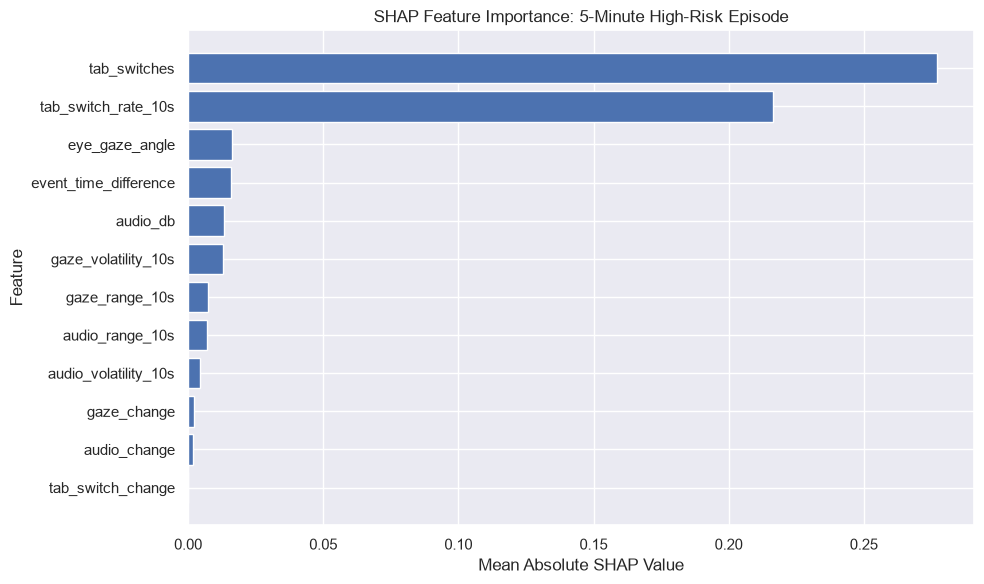

In [188]:
# 11G. EPISODE-LEVEL SHAP FEATURE IMPORTANCE

import matplotlib.pyplot as plt

plot_df = shap_summary.sort_values(
    "Mean_Absolute_SHAP", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    plot_df["Feature"],
    plot_df["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("SHAP Feature Importance: 5-Minute High-Risk Episode")
plt.tight_layout()
plt.show()

In [191]:

# ============================================================
# 11H. EXPLAIN ONE HIGH-RISK OBSERVATION
# ============================================================

X_one = X_episode.iloc[[0]]
one_shap = shap_values[0]

# Support SHAP output as a NumPy array
if isinstance(one_shap, np.ndarray):
    contribution_values = one_shap[:, 1]
else:
    contribution_values = one_shap.values[:, 1]

local_explanation = pd.DataFrame({
    "Feature": causal_feature_columns,
    "Feature_Value": X_one.iloc[0].values,
    "SHAP_Contribution": contribution_values
})

local_explanation["Abs_Contribution"] = (
    local_explanation["SHAP_Contribution"].abs()
)

local_explanation = local_explanation.sort_values(
    "Abs_Contribution",
    ascending=False
)

print("Observation timestamp:", X_one.index[0])
print("\nLocal feature contributions:")
print(local_explanation.round(5).to_string(index=False))


Observation timestamp: 9606

Local feature contributions:
              Feature  Feature_Value  SHAP_Contribution  Abs_Contribution
         tab_switches        3.00000            0.18454           0.18454
       eye_gaze_angle       43.29828            0.09095           0.09095
             audio_db       61.90620            0.08387           0.08387
  tab_switch_rate_10s        1.20000            0.06305           0.06305
       gaze_range_10s       14.05360            0.02478           0.02478
  gaze_volatility_10s        4.53250            0.02441           0.02441
      audio_range_10s       12.58529            0.00980           0.00980
    tab_switch_change        2.00000           -0.00355           0.00355
 audio_volatility_10s        4.30320            0.00286           0.00286
event_time_difference        0.83593            0.00283           0.00283
          gaze_change       12.71239           -0.00091           0.00091
         audio_change        4.10109           -0.0001

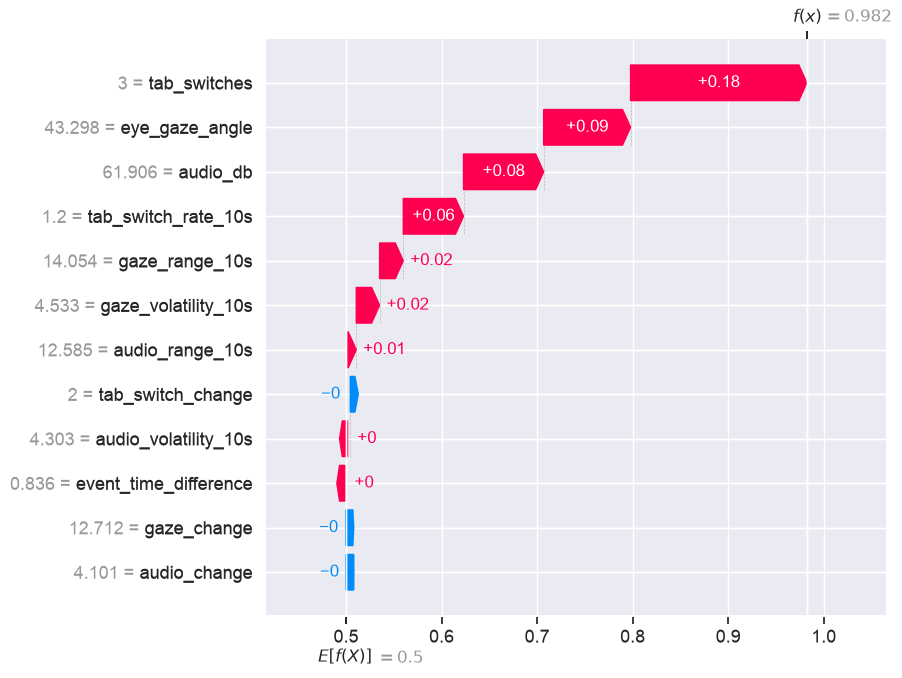

In [193]:

# ============================================================
# 11I. LOCAL SHAP WATERFALL
# ============================================================

local_shap = shap_values[0, :, 1]

local_explanation_plot = shap.Explanation(
    values=local_shap,
    base_values=explainer.expected_value[1],
    data=X_episode.iloc[0].to_numpy(),
    feature_names=causal_feature_columns
)

shap.plots.waterfall(
    local_explanation_plot,
    max_display=12,
    show=True
)


In [194]:
# 11J. BUILD REVIEW EVIDENCE REPORT

evidence_report = {
    "episode_start": episode_start,
    "episode_end": episode_end,
    "duration_seconds": int(longest_episode["Duration_Seconds"]),
    "observations": len(episode_rows),
    "mean_risk_score": round(episode_rows["risk_score"].mean(), 4),
    "max_risk_score": round(episode_rows["risk_score"].max(), 4),
    "median_tab_switches": episode_rows["tab_switches"].median(),
    "median_gaze_angle": round(
        episode_rows["eye_gaze_angle"].median(), 3
    ),
    "median_audio_db": round(
        episode_rows["audio_db"].median(), 3
    ),
    "top_model_contributors": shap_summary.head(5)["Feature"].tolist(),
    "review_recommendation": (
        "Human review recommended; model output is not proof of misconduct."
    )
}

for key, value in evidence_report.items():
    print(f"{key}: {value}")

episode_start: 2023-12-01 10:40:40
episode_end: 2023-12-01 10:45:39
duration_seconds: 300
observations: 300
mean_risk_score: 0.9962
max_risk_score: 1.0
median_tab_switches: 3.0
median_gaze_angle: 5.415
median_audio_db: 35.402
top_model_contributors: ['tab_switches', 'tab_switch_rate_10s', 'eye_gaze_angle', 'event_time_difference', 'audio_db']
review_recommendation: Human review recommended; model output is not proof of misconduct.


In [195]:
# 12A. EXPORT EPISODE EVIDENCE

evidence_df = pd.DataFrame([evidence_report])

evidence_df.to_csv(
    "executive_panopticon_evidence_report.csv",
    index=False
)

print("Evidence report saved.")
print("Shape:", evidence_df.shape)
print("File: executive_panopticon_evidence_report.csv")

Evidence report saved.
Shape: (1, 11)
File: executive_panopticon_evidence_report.csv


In [196]:
# 12B. VERIFY EXPORTED REPORT

from pathlib import Path

report_path = Path("executive_panopticon_evidence_report.csv")

print("File exists:", report_path.exists())
print("File size:", report_path.stat().st_size, "bytes")
print("\nSaved report:")
print(pd.read_csv(report_path).T.to_string(header=False))

File exists: True
File size: 426 bytes

Saved report:
episode_start                                                                                      2023-12-01 10:40:40
episode_end                                                                                        2023-12-01 10:45:39
duration_seconds                                                                                                   300
observations                                                                                                       300
mean_risk_score                                                                                                 0.9962
max_risk_score                                                                                                     1.0
median_tab_switches                                                                                                3.0
median_gaze_angle                                                                                                

In [198]:
# 12C. CHECK DASHBOARD LIBRARIES

import importlib.util

for library in ["streamlit", "plotly", "ipywidgets"]:
    print(f"{library}:",
          "Installed" if importlib.util.find_spec(library) else "Not installed")

streamlit: Not installed
plotly: Not installed
ipywidgets: Installed


In [199]:
# 12D. PREPARE DASHBOARD DATA

print("Risk episodes:", len(causal_risk_runs))
print("Risk event observations:", len(causal_risk_events))
print("\nEpisode columns:")
print(causal_risk_runs.columns.tolist())

print("\nEpisode preview:")
display(causal_risk_runs.head())

Risk episodes: 13
Risk event observations: 1994

Episode columns:
['Start', 'End', 'Duration_Seconds', 'Observations', 'Mean_Risk', 'Max_Risk', 'Severity_Score', 'Severity_Level']

Episode preview:


,Start,End,Duration_Seconds,Observations,Mean_Risk,Max_Risk,Severity_Score,Severity_Level
0,2023-12-01 10:13:26,2023-12-01 10:13:26,1.0,1,0.747401,0.747401,1.265460,Low
1,2023-12-01 10:14:48,2023-12-01 10:14:48,1.0,1,0.714668,0.714668,1.210038,Low
2,2023-12-01 10:21:11,2023-12-01 10:21:14,4.0,4,0.666470,0.682759,1.739112,Low
3,2023-12-01 10:23:48,2023-12-01 10:23:54,7.0,7,0.741363,0.766447,2.282983,Moderate
4,2023-12-01 10:27:20,2023-12-01 10:28:17,58.0,58,0.989203,1.000000,5.022718,High


In [200]:
# 12E. INTERACTIVE RISK REVIEW DASHBOARD

import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd

episodes = causal_risk_runs.copy().reset_index(drop=True)

# Summary cards
total_episodes = len(episodes)
high_episodes = episodes["Severity_Level"].astype(str).isin(
    ["High", "Critical"]
).sum()
longest_duration = episodes["Duration_Seconds"].max()
mean_episode_risk = episodes["Mean_Risk"].mean()

summary = widgets.HTML(
    value=f"""
    <div style="display:flex;gap:12px;flex-wrap:wrap;">
      <div style="border:1px solid #bbb;padding:14px;border-radius:8px;">
        <b>Flagged episodes</b><br><span style="font-size:24px">{total_episodes}</span>
      </div>
      <div style="border:1px solid #bbb;padding:14px;border-radius:8px;">
        <b>High / Critical</b><br><span style="font-size:24px">{high_episodes}</span>
      </div>
      <div style="border:1px solid #bbb;padding:14px;border-radius:8px;">
        <b>Longest episode</b><br><span style="font-size:24px">{longest_duration:.0f}s</span>
      </div>
      <div style="border:1px solid #bbb;padding:14px;border-radius:8px;">
        <b>Mean episode risk</b><br><span style="font-size:24px">{mean_episode_risk:.3f}</span>
      </div>
    </div>
    <p style="color:#777">Risk flags indicate cases for review, not proof of misconduct.</p>
    """
)

display(widgets.VBox([
    widgets.HTML("<h3>Executive Panopticon — Risk Review</h3>"),
    summary
]))

display(
    episodes[
        ["Start", "End", "Duration_Seconds",
         "Mean_Risk", "Max_Risk", "Severity_Level"]
    ].style.format({
        "Mean_Risk": "{:.3f}",
        "Max_Risk": "{:.3f}",
        "Duration_Seconds": "{:.0f}"
    })
)

,Start,End,Duration_Seconds,Mean_Risk,Max_Risk,Severity_Level
0,2023-12-01 10:13:26,2023-12-01 10:13:26,1,0.747,0.747,Low
1,2023-12-01 10:14:48,2023-12-01 10:14:48,1,0.715,0.715,Low
2,2023-12-01 10:21:11,2023-12-01 10:21:14,4,0.666,0.683,Low
3,2023-12-01 10:23:48,2023-12-01 10:23:54,7,0.741,0.766,Moderate
4,2023-12-01 10:27:20,2023-12-01 10:28:17,58,0.989,1.000,High
5,2023-12-01 10:29:33,2023-12-01 10:29:33,1,0.670,0.670,Low
6,2023-12-01 10:29:36,2023-12-01 10:29:36,1,0.666,0.666,Low
7,2023-12-01 10:29:38,2023-12-01 10:30:06,29,0.963,1.000,High
8,2023-12-01 10:30:46,2023-12-01 10:31:05,20,0.959,1.000,Moderate
9,2023-12-01 10:32:27,2023-12-01 10:32:36,10,0.867,0.978,Moderate


In [201]:
# 12F. INTERACTIVE EPISODE EXPLORER

from IPython.display import display, HTML
import ipywidgets as widgets
import pandas as pd
import numpy as np

episode_options = [
    (f"Episode {i + 1} | {row.Start} | "
     f"{row.Duration_Seconds:.0f}s | Risk {row.Mean_Risk:.3f}", i)
    for i, row in episodes.iterrows()
]

episode_selector = widgets.Dropdown(
    options=episode_options,
    description="Episode:",
    layout=widgets.Layout(width="95%"),
    style={"description_width": "initial"}
)

episode_output = widgets.Output()

def show_episode(index):
    row = episodes.iloc[index]

    selected_rows = causal_risk_events[
        causal_risk_events["timestamp"].between(row["Start"], row["End"])
    ].copy()

    with episode_output:
        episode_output.clear_output(wait=True)

        display(HTML(f"""
        <h3>Episode {index + 1}</h3>
        <p><b>Start:</b> {row['Start']} &nbsp; 
        <b>End:</b> {row['End']}</p>
        <p><b>Duration:</b> {row['Duration_Seconds']:.0f} seconds &nbsp;
        <b>Mean risk:</b> {row['Mean_Risk']:.3f} &nbsp;
        <b>Severity:</b> {row['Severity_Level']}</p>
        """))

        if selected_rows.empty:
            print("No matching observations found.")
            return

        display(selected_rows[
            ["timestamp", "risk_score", "tab_switches",
             "eye_gaze_angle", "audio_db"]
        ].head(10).round(3))

        print("Top SHAP contributors:")
        if row["Start"] == episode_start and row["End"] == episode_end:
            display(shap_summary.head(5).round(4))
        else:
            print("Episode-level SHAP values have not yet been calculated for this episode.")

def on_episode_change(change):
    if change["name"] == "value":
        show_episode(change["new"])

episode_selector.observe(on_episode_change, names="value")

display(episode_selector, episode_output)
show_episode(episode_selector.value)

/var/folders/47/qjpttn957c56md50j7dz0xxh0000gn/T/ipykernel_90592/1382936503.py:49: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(3))


,timestamp,risk_score,tab_switches,eye_gaze_angle,audio_db
7972,2023-12-01 10:13:26,0.747,1.0,8.291,37.679


Top SHAP contributors:
Episode-level SHAP values have not yet been calculated for this episode.


In [202]:
# 12G. DYNAMIC EPISODE EXPLANATIONS

def show_episode(index):
    row = episodes.iloc[index]

    selected_rows = causal_risk_events[
        causal_risk_events["timestamp"].between(
            row["Start"], row["End"]
        )
    ].copy()

    with episode_output:
        episode_output.clear_output(wait=True)

        display(HTML(f"""
        <h3>Episode {index + 1}</h3>
        <p><b>Start:</b> {row['Start']} &nbsp;
        <b>End:</b> {row['End']}</p>
        <p><b>Duration:</b> {row['Duration_Seconds']:.0f} seconds &nbsp;
        <b>Mean risk:</b> {row['Mean_Risk']:.3f} &nbsp;
        <b>Severity:</b> {row['Severity_Level']}</p>
        """))

        if selected_rows.empty:
            print("No matching observations found.")
            return

        display(
            selected_rows[
                ["timestamp", "risk_score", "tab_switches",
                 "eye_gaze_angle", "audio_db"]
            ].head(10).round({
                "risk_score": 3,
                "tab_switches": 2,
                "eye_gaze_angle": 2,
                "audio_db": 2
            })
        )

        # Calculate SHAP values for this episode
        X_selected = selected_rows[causal_feature_columns]
        selected_shap = explainer(X_selected)
        class_1_values = selected_shap.values[:, :, 1]

        local_summary = pd.DataFrame({
            "Feature": causal_feature_columns,
            "Mean_SHAP": class_1_values.mean(axis=0),
            "Mean_Absolute_SHAP": np.abs(class_1_values).mean(axis=0)
        }).sort_values("Mean_Absolute_SHAP", ascending=False)

        print("\nTop SHAP contributors for this episode:")
        display(local_summary.head(5).round(5))

        print(
            "\nInterpretation: positive SHAP values push the model "
            "toward class 1; negative values push it away. "
            "These contributions are not proof of misconduct."
        )

episode_selector.unobserve(on_episode_change, names="value")
episode_selector.observe(on_episode_change, names="value")

show_episode(episode_selector.value)

,timestamp,risk_score,tab_switches,eye_gaze_angle,audio_db
7972,2023-12-01 10:13:26,0.747,1.0,8.29,37.68



Top SHAP contributors for this episode:


,Feature,Mean_SHAP,Mean_Absolute_SHAP
0,eye_gaze_angle,0.11858,0.11858
3,event_time_difference,0.10243,0.10243
2,tab_switches,-0.09096,0.09096
8,tab_switch_rate_10s,-0.05169,0.05169
1,audio_db,0.03963,0.03963



Interpretation: positive SHAP values push the model toward class 1; negative values push it away. These contributions are not proof of misconduct.


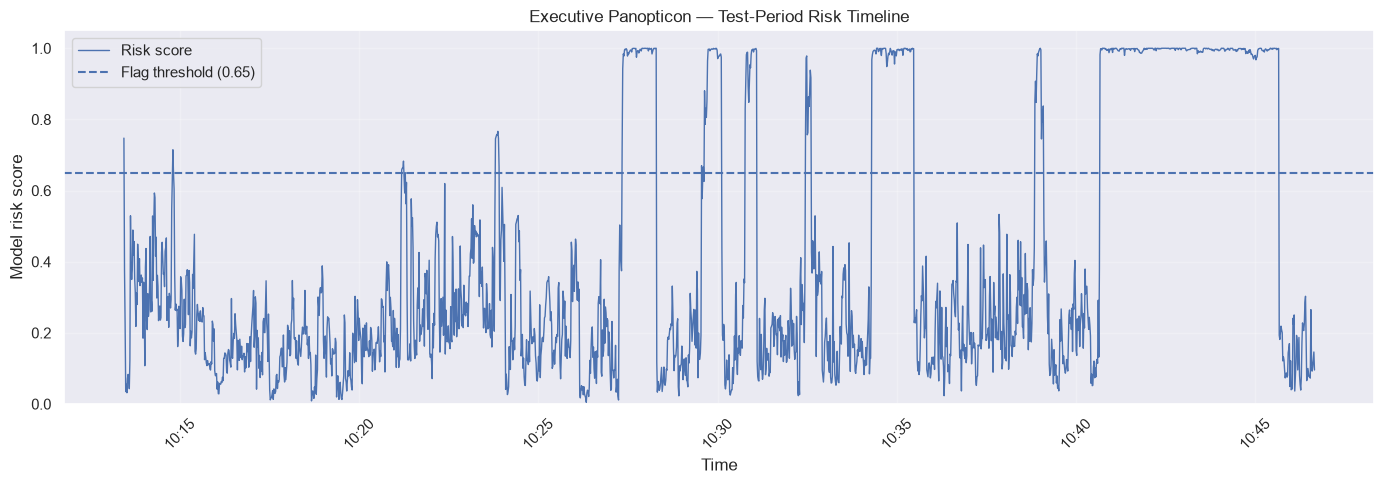

In [203]:
# 12H. RISK TIMELINE

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

timeline_df = causal_risk_events.sort_values("timestamp")

plt.figure(figsize=(14, 5))
plt.plot(
    timeline_df["timestamp"],
    timeline_df["risk_score"],
    linewidth=1,
    label="Risk score"
)
plt.axhline(
    0.65,
    linestyle="--",
    linewidth=1.5,
    label="Flag threshold (0.65)"
)

plt.xlabel("Time")
plt.ylabel("Model risk score")
plt.title("Executive Panopticon — Test-Period Risk Timeline")
plt.ylim(0, 1.05)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

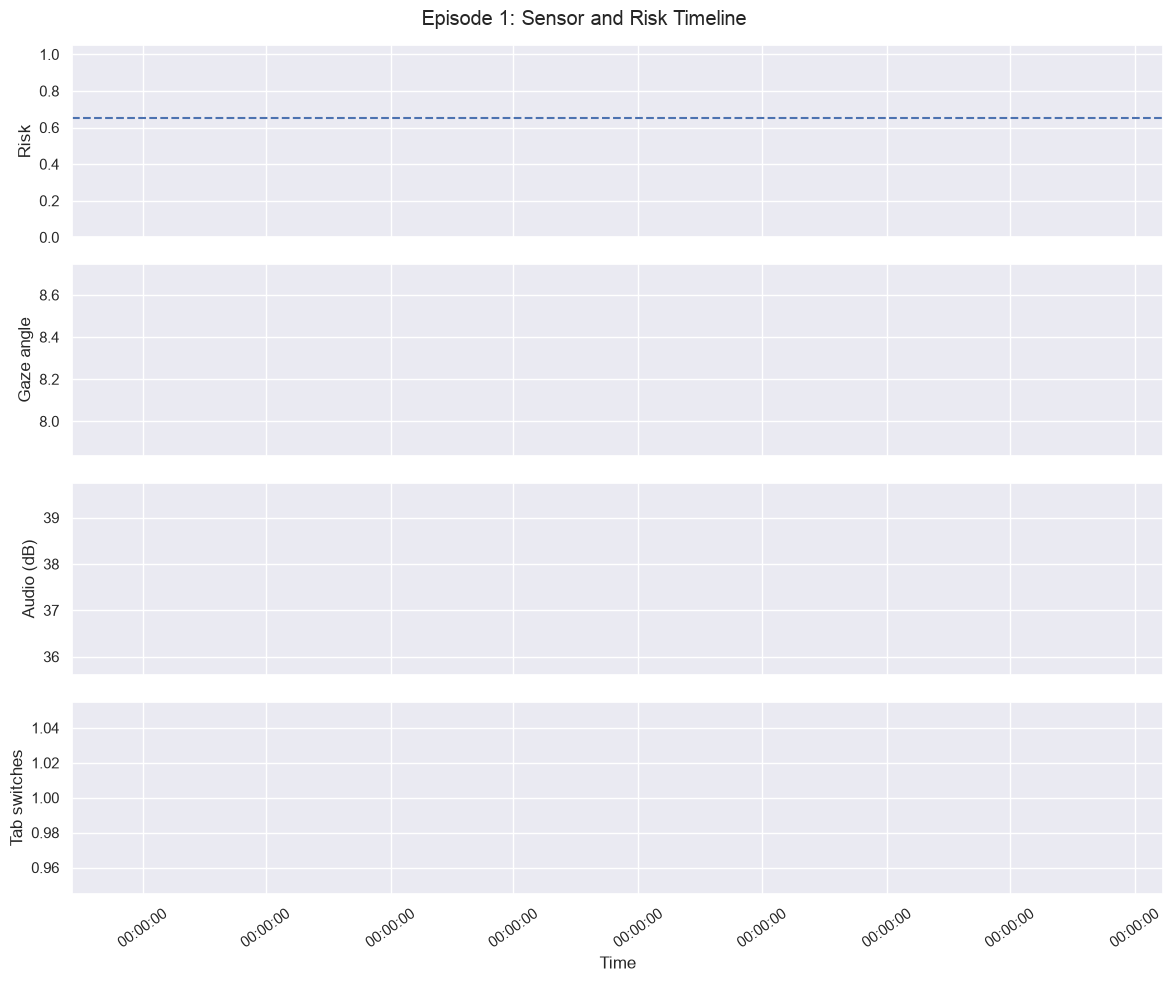

In [204]:
# 12I. SELECTED EPISODE SENSOR TIMELINE

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_selected_episode(index):
    row = episodes.iloc[index]

    selected_rows = causal_risk_events[
        causal_risk_events["timestamp"].between(
            row["Start"], row["End"]
        )
    ].copy()

    if selected_rows.empty:
        print("No observations found for this episode.")
        return

    fig, axes = plt.subplots(
        4, 1, figsize=(12, 10), sharex=True
    )

    axes[0].plot(
        selected_rows["timestamp"],
        selected_rows["risk_score"]
    )
    axes[0].axhline(0.65, linestyle="--")
    axes[0].set_ylabel("Risk")
    axes[0].set_ylim(0, 1.05)

    axes[1].plot(
        selected_rows["timestamp"],
        selected_rows["eye_gaze_angle"]
    )
    axes[1].set_ylabel("Gaze angle")

    axes[2].plot(
        selected_rows["timestamp"],
        selected_rows["audio_db"]
    )
    axes[2].set_ylabel("Audio (dB)")

    axes[3].step(
        selected_rows["timestamp"],
        selected_rows["tab_switches"],
        where="post"
    )
    axes[3].set_ylabel("Tab switches")
    axes[3].set_xlabel("Time")

    axes[3].xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M:%S")
    )

    fig.suptitle(
        f"Episode {index + 1}: Sensor and Risk Timeline"
    )
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()


plot_selected_episode(episode_selector.value)

Episode: 1
Observations: 1

Missing values:
risk_score        0
eye_gaze_angle    0
audio_db          0
tab_switches      0
dtype: int64


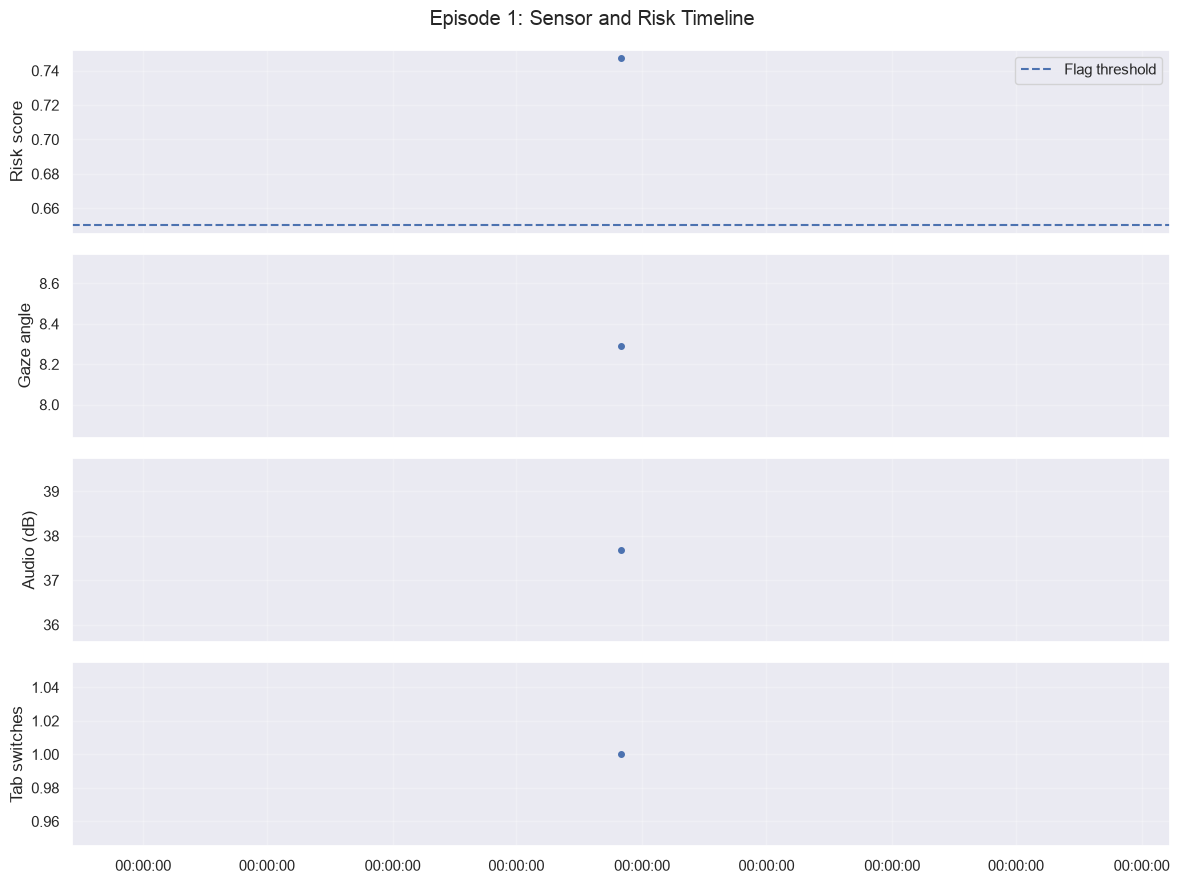

In [205]:
# 12J. FIXED EPISODE SENSOR TIMELINE

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_selected_episode(index):
    row = episodes.iloc[index]

    selected_rows = causal_risk_events[
        causal_risk_events["timestamp"].between(
            row["Start"], row["End"]
        )
    ].copy()

    print("Episode:", index + 1)
    print("Observations:", len(selected_rows))

    if selected_rows.empty:
        print("No observations found for this episode.")
        return

    columns = [
        "risk_score", "eye_gaze_angle",
        "audio_db", "tab_switches"
    ]

    print("\nMissing values:")
    print(selected_rows[columns].isna().sum())

    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

    plot_specs = [
        ("risk_score", "Risk score"),
        ("eye_gaze_angle", "Gaze angle"),
        ("audio_db", "Audio (dB)"),
        ("tab_switches", "Tab switches")
    ]

    for ax, (column, label) in zip(axes, plot_specs):
        ax.plot(
            selected_rows["timestamp"],
            selected_rows[column],
            marker="o",
            markersize=4,
            linewidth=1
        )
        ax.set_ylabel(label)
        ax.grid(alpha=0.25)

    axes[0].axhline(0.65, linestyle="--", label="Flag threshold")
    axes[0].legend()

    axes[-1].xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M:%S")
    )

    fig.suptitle(f"Episode {index + 1}: Sensor and Risk Timeline")
    plt.tight_layout()
    plt.show()

plot_selected_episode(episode_selector.value)

,timestamp,risk_score,tab_switches,eye_gaze_angle,audio_db
9606,2023-12-01 10:40:40,0.982,3.0,43.30,61.91
9607,2023-12-01 10:40:41,0.999,3.0,42.70,71.59
9608,2023-12-01 10:40:42,0.998,3.0,44.71,58.18
9609,2023-12-01 10:40:43,0.995,3.0,44.36,63.97
9610,2023-12-01 10:40:44,1.000,3.0,46.92,62.58
9611,2023-12-01 10:40:45,1.000,3.0,46.50,73.56
9612,2023-12-01 10:40:46,1.000,3.0,42.61,65.02
9613,2023-12-01 10:40:47,0.999,3.0,46.68,69.51
9614,2023-12-01 10:40:48,1.000,3.0,46.09,62.39
9615,2023-12-01 10:40:49,0.998,3.0,41.80,62.03



Top SHAP contributors for this episode:


,Feature,Mean_SHAP,Mean_Absolute_SHAP
2,tab_switches,0.27692,0.27692
8,tab_switch_rate_10s,0.21628,0.21628
0,eye_gaze_angle,-0.00030,0.01619
3,event_time_difference,0.00648,0.01581
1,audio_db,0.00046,0.01318



Interpretation: positive SHAP values push the model toward class 1; negative values push it away. These contributions are not proof of misconduct.
Episode: 13
Observations: 300

Missing values:
risk_score        0
eye_gaze_angle    0
audio_db          0
tab_switches      0
dtype: int64


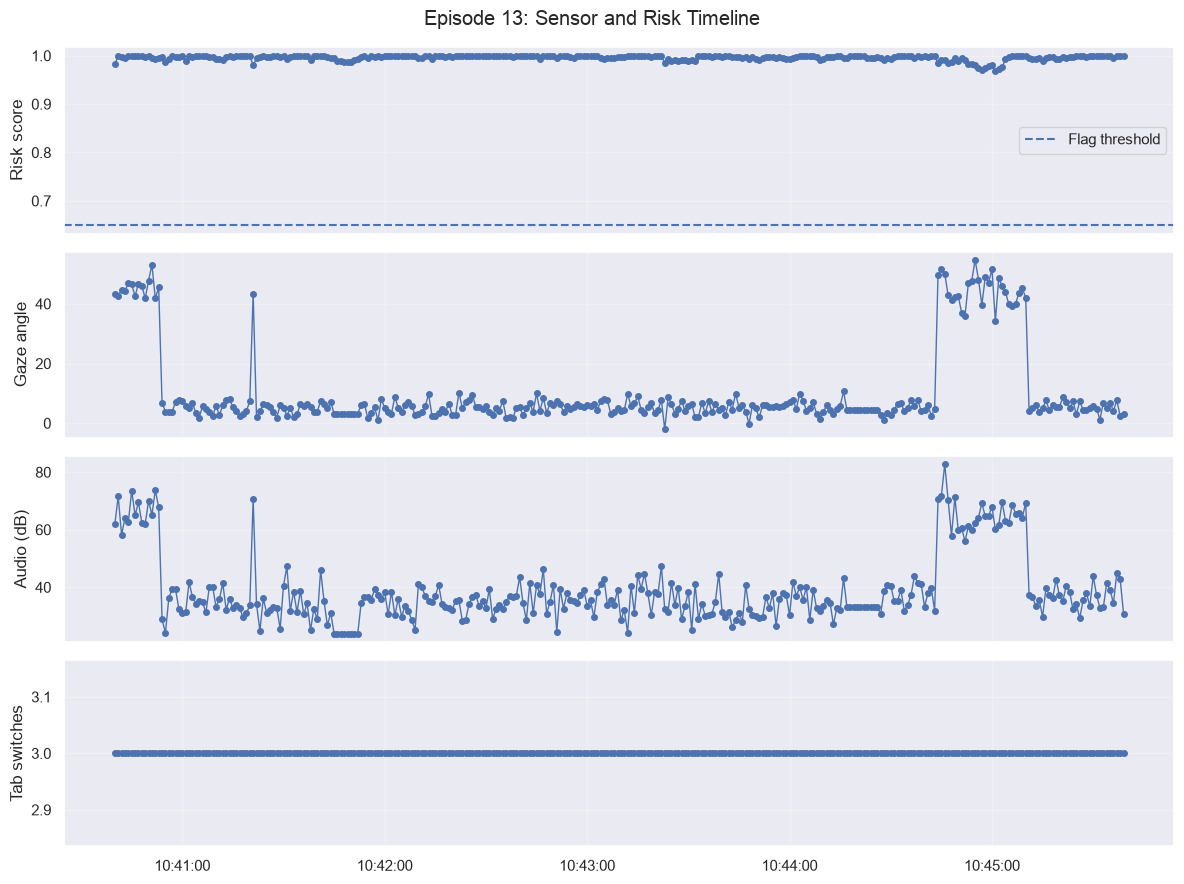

In [206]:
# 12K. PLOT THE LONGEST EPISODE

longest_index = episodes["Duration_Seconds"].idxmax()

episode_selector.value = int(longest_index)
plot_selected_episode(int(longest_index))

In [208]:

# 12L. LINK DROPDOWN TO SENSOR TIMELINE

def update_episode_timeline(change):
    if change["name"] == "value":
        plot_selected_episode(change["new"])

# Remove this callback if it was already registered.
# Ignore the error if it was not registered.
try:
    episode_selector.unobserve(
        update_episode_timeline,
        names="value"
    )
except ValueError:
    pass

episode_selector.observe(
    update_episode_timeline,
    names="value"
)

print("Timeline connected to episode selector.")
print("Choose another episode from the dropdown to update the chart.")


Timeline connected to episode selector.
Choose another episode from the dropdown to update the chart.


In [209]:
# 12L. LINK DROPDOWN TO SENSOR TIMELINE

def update_episode_timeline(change):
    if change["name"] == "value":
        plot_selected_episode(change["new"])

# Register the callback
episode_selector.observe(
    update_episode_timeline,
    names="value"
)

print("Timeline connected to episode selector.")
print("Change the dropdown to update the chart.")

Timeline connected to episode selector.
Change the dropdown to update the chart.


Episode: 13
Observations: 300

Missing values:
risk_score        0
eye_gaze_angle    0
audio_db          0
tab_switches      0
dtype: int64


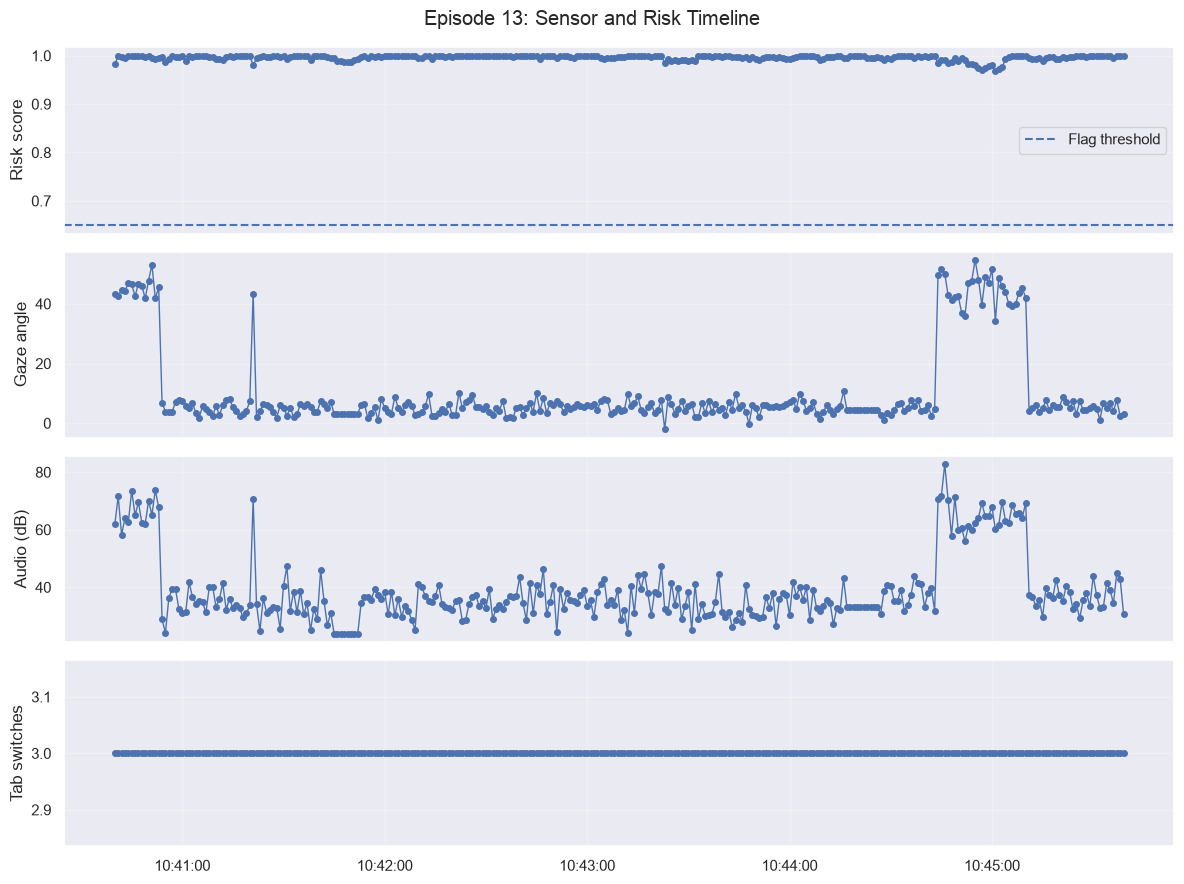

In [210]:
# 12K. PLOT THE LONGEST EPISODE

longest_index = episodes["Duration_Seconds"].idxmax()

episode_selector.value = int(longest_index)
plot_selected_episode(int(longest_index))

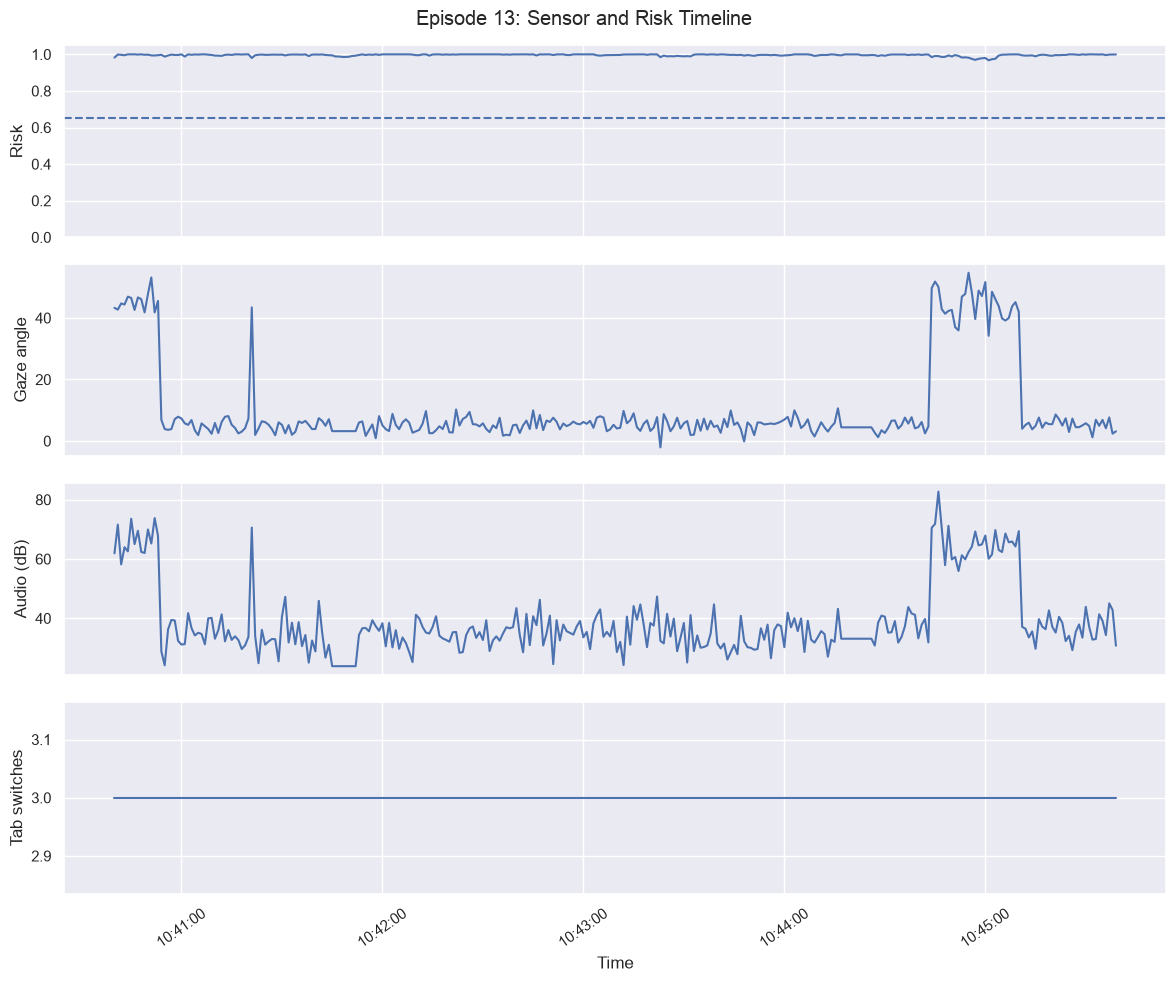

In [215]:
# 12I. SELECTED EPISODE SENSOR TIMELINE

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_selected_episode(index):
    row = episodes.iloc[index]

    selected_rows = causal_risk_events[
        causal_risk_events["timestamp"].between(
            row["Start"], row["End"]
        )
    ].copy()

    if selected_rows.empty:
        print("No observations found for this episode.")
        return

    fig, axes = plt.subplots(
        4, 1, figsize=(12, 10), sharex=True
    )

    axes[0].plot(
        selected_rows["timestamp"],
        selected_rows["risk_score"]
    )
    axes[0].axhline(0.65, linestyle="--")
    axes[0].set_ylabel("Risk")
    axes[0].set_ylim(0, 1.05)

    axes[1].plot(
        selected_rows["timestamp"],
        selected_rows["eye_gaze_angle"]
    )
    axes[1].set_ylabel("Gaze angle")

    axes[2].plot(
        selected_rows["timestamp"],
        selected_rows["audio_db"]
    )
    axes[2].set_ylabel("Audio (dB)")

    axes[3].step(
        selected_rows["timestamp"],
        selected_rows["tab_switches"],
        where="post"
    )
    axes[3].set_ylabel("Tab switches")
    axes[3].set_xlabel("Time")

    axes[3].xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M:%S")
    )

    fig.suptitle(
        f"Episode {index + 1}: Sensor and Risk Timeline"
    )
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()


plot_selected_episode(episode_selector.value)

In [131]:
# 12N. RESET EPISODE DROPDOWN CALLBACKS

# Remove all existing value-change observers
episode_selector.unobserve_all("value")

def refresh_episode(change):
    index = change["new"]

    # Update episode details and SHAP output
    show_episode(index)

    # Update the sensor timeline
    plot_selected_episode(index)

# Register one unified callback
episode_selector.observe(refresh_episode, names="value")

print("Dropdown callbacks reset.")
print("Select Episode 5 to test the update.")

Dropdown callbacks reset.
Select Episode 5 to test the update.


In [214]:
# 12O. FIX SINGLE-POINT EPISODE PLOTTING

def plot_selected_episode(index):
    row = episodes.iloc[index]

    selected_rows = causal_risk_events[
        causal_risk_events["timestamp"].between(
            row["Start"], row["End"]
        )
    ].copy()

    print(f"Episode: {index + 1}")
    print(f"Observations: {len(selected_rows)}")

    if selected_rows.empty:
        print("No observations found.")
        return

    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

    plot_specs = [
        ("risk_score", "Risk score"),
        ("eye_gaze_angle", "Gaze angle"),
        ("audio_db", "Audio (dB)"),
        ("tab_switches", "Tab switches")
    ]

    for ax, (column, label) in zip(axes, plot_specs):
        ax.plot(
            selected_rows["timestamp"],
            selected_rows[column],
            marker="o",
            markersize=5,
            linewidth=1
        )
        ax.set_ylabel(label)
        ax.grid(alpha=0.25)

    axes[0].axhline(0.65, linestyle="--", label="Flag threshold")
    axes[0].legend()

    axes[-1].xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M:%S")
    )

    fig.suptitle(f"Episode {index + 1}: Sensor and Risk Timeline")
    plt.tight_layout()
    plt.show()

Episode: 13
Observations: 300


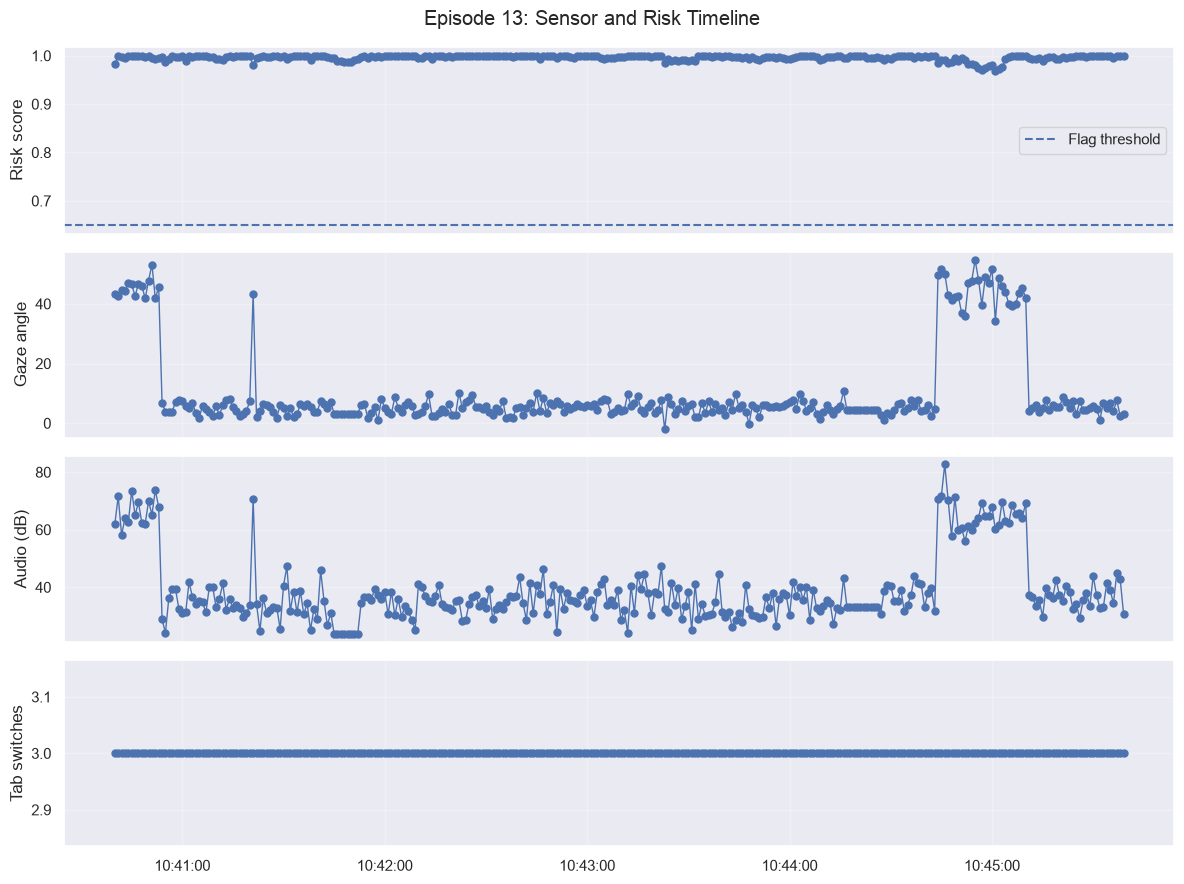

In [138]:
plot_selected_episode(episode_selector.value)

/var/folders/47/qjpttn957c56md50j7dz0xxh0000gn/T/ipykernel_90592/1382936503.py:49: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(3))


,timestamp,risk_score,tab_switches,eye_gaze_angle,audio_db
8806,2023-12-01 10:27:20,0.714,1.0,44.026,66.488
8807,2023-12-01 10:27:21,0.943,2.0,36.116,67.857
8808,2023-12-01 10:27:22,0.984,2.0,46.289,68.012
8809,2023-12-01 10:27:23,0.978,2.0,45.633,67.819
8810,2023-12-01 10:27:24,0.995,2.0,42.076,69.941
8811,2023-12-01 10:27:25,0.997,2.0,45.925,65.998
8812,2023-12-01 10:27:26,0.996,2.0,51.754,66.105
8813,2023-12-01 10:27:27,0.999,2.0,46.842,63.391
8814,2023-12-01 10:27:28,0.995,2.0,40.831,69.307
8815,2023-12-01 10:27:29,0.978,2.0,44.597,70.871


Top SHAP contributors:
Episode-level SHAP values have not yet been calculated for this episode.
Episode: 5
Observations: 58


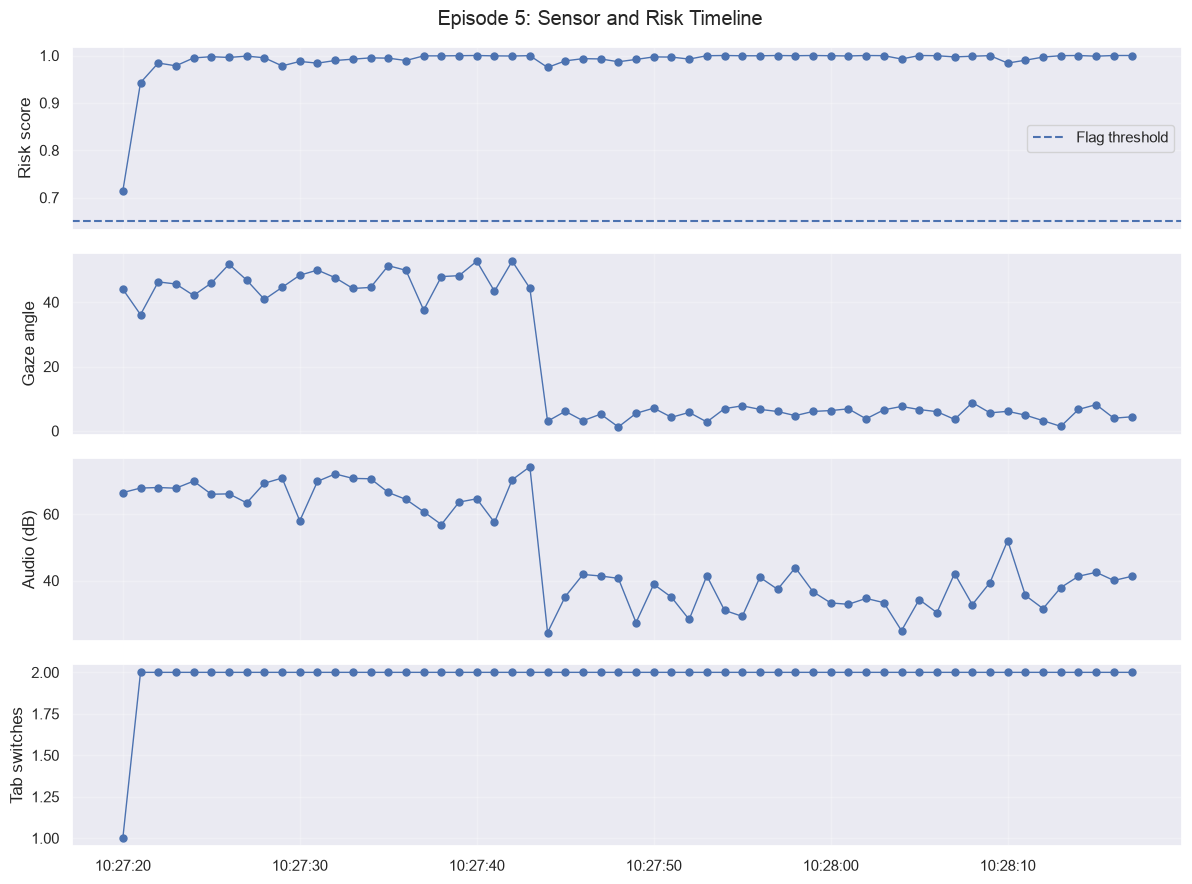

Selected episode: 5


In [139]:
# 12P. TEST EPISODE 5

episode_selector.value = 4  # Episode 5 (zero-based index)
print("Selected episode:", episode_selector.value + 1)

In [140]:
# 12Q. FIX DYNAMIC SHAP EXPLANATIONS

def show_episode(index):
    row = episodes.iloc[index]

    selected_rows = causal_risk_events[
        causal_risk_events["timestamp"].between(
            row["Start"], row["End"]
        )
    ].copy()

    with episode_output:
        episode_output.clear_output(wait=True)

        display(HTML(f"""
        <h3>Episode {index + 1}</h3>
        <p><b>Start:</b> {row['Start']} &nbsp;
        <b>End:</b> {row['End']}</p>
        <p><b>Duration:</b> {row['Duration_Seconds']:.0f} seconds &nbsp;
        <b>Mean risk:</b> {row['Mean_Risk']:.3f} &nbsp;
        <b>Severity:</b> {row['Severity_Level']}</p>
        """))

        if selected_rows.empty:
            print("No observations found.")
            return

        # Display observations without datetime rounding warnings
        display(
            selected_rows[
                ["timestamp", "risk_score", "tab_switches",
                 "eye_gaze_angle", "audio_db"]
            ].head(10).round({
                "risk_score": 3,
                "tab_switches": 2,
                "eye_gaze_angle": 2,
                "audio_db": 2
            })
        )

        # Calculate SHAP for the selected episode
        X_selected = selected_rows[causal_feature_columns]
        selected_shap = explainer(X_selected)
        class_1_shap = selected_shap.values[:, :, 1]

        episode_shap_summary = pd.DataFrame({
            "Feature": causal_feature_columns,
            "Mean_SHAP": class_1_shap.mean(axis=0),
            "Mean_Absolute_SHAP": np.abs(class_1_shap).mean(axis=0)
        }).sort_values(
            "Mean_Absolute_SHAP", ascending=False
        )

        print("\nTop 5 SHAP contributors:")
        display(episode_shap_summary.head(5).round(5))

        print(
            "\nPositive SHAP: increases model class-1 score."
            "\nNegative SHAP: decreases model class-1 score."
            "\nHuman review required; predictions are not proof of misconduct."
        )

# Refresh the currently selected episode
show_episode(episode_selector.value)

,timestamp,risk_score,tab_switches,eye_gaze_angle,audio_db
8806,2023-12-01 10:27:20,0.714,1.0,44.03,66.49
8807,2023-12-01 10:27:21,0.943,2.0,36.12,67.86
8808,2023-12-01 10:27:22,0.984,2.0,46.29,68.01
8809,2023-12-01 10:27:23,0.978,2.0,45.63,67.82
8810,2023-12-01 10:27:24,0.995,2.0,42.08,69.94
8811,2023-12-01 10:27:25,0.997,2.0,45.93,66.00
8812,2023-12-01 10:27:26,0.996,2.0,51.75,66.11
8813,2023-12-01 10:27:27,0.999,2.0,46.84,63.39
8814,2023-12-01 10:27:28,0.995,2.0,40.83,69.31
8815,2023-12-01 10:27:29,0.978,2.0,44.60,70.87



Top 5 SHAP contributors:


,Feature,Mean_SHAP,Mean_Absolute_SHAP
2,tab_switches,0.24117,0.24423
8,tab_switch_rate_10s,0.18188,0.18428
0,eye_gaze_angle,0.02689,0.03643
1,audio_db,0.02466,0.03281
6,gaze_volatility_10s,0.00814,0.01697



Positive SHAP: increases model class-1 score.
Negative SHAP: decreases model class-1 score.
Human review required; predictions are not proof of misconduct.


In [141]:
# 12R. VALIDATE ALL EPISODES

test_results = []

for index, row in episodes.reset_index(drop=True).iterrows():
    selected_rows = causal_risk_events[
        causal_risk_events["timestamp"].between(
            row["Start"], row["End"]
        )
    ]

    result = {
        "Episode": index + 1,
        "Observations": len(selected_rows),
        "Expected_Observations": int(row["Observations"]),
        "Data_OK": len(selected_rows) == int(row["Observations"]),
        "SHAP_OK": False,
        "Error": ""
    }

    try:
        if selected_rows.empty:
            raise ValueError("No matching risk observations")

        X_selected = selected_rows[causal_feature_columns]
        shap_result = explainer(X_selected)

        shap_values = np.asarray(shap_result.values)

        if shap_values.ndim == 3:
            class_1_shap = shap_values[:, :, 1]
        elif shap_values.ndim == 2:
            class_1_shap = shap_values
        else:
            raise ValueError(f"Unexpected SHAP shape: {shap_values.shape}")

        result["SHAP_OK"] = (
            class_1_shap.shape == (
                len(selected_rows), len(causal_feature_columns)
            )
            and np.isfinite(class_1_shap).all()
        )

        if not result["SHAP_OK"]:
            result["Error"] = "Invalid SHAP shape or non-finite values"

    except Exception as exc:
        result["Error"] = str(exc)

    test_results.append(result)

test_report = pd.DataFrame(test_results)

display(test_report)

print("\nEpisodes tested:", len(test_report))
print("Data checks passed:", int(test_report["Data_OK"].sum()))
print("SHAP checks passed:", int(test_report["SHAP_OK"].sum()))
print(
    "Overall:",
    "PASS" if test_report["Data_OK"].all()
    and test_report["SHAP_OK"].all()
    else "CHECK FAILURES"
)

,Episode,Observations,Expected_Observations,Data_OK,SHAP_OK,Error
0,1,1,1,True,True,
1,2,1,1,True,True,
2,3,4,4,True,True,
3,4,7,7,True,True,
4,5,58,58,True,True,
5,6,1,1,True,True,
6,7,1,1,True,True,
7,8,29,29,True,True,
8,9,20,20,True,True,
9,10,10,10,True,True,



Episodes tested: 13
Data checks passed: 13
SHAP checks passed: 13
Overall: PASS


In [142]:
# 12S. VERIFY EPISODE COUNTS

count_check = pd.DataFrame({
    "Episode": range(1, len(episodes) + 1),
    "Expected": episodes["Observations"].astype(int).to_numpy(),
    "Actual": [
        causal_risk_events["timestamp"].between(
            row["Start"], row["End"]
        ).sum()
        for _, row in episodes.iterrows()
    ]
})

count_check["Match"] = (
    count_check["Expected"] == count_check["Actual"]
)

display(count_check.to_string(index=False))
print("\nAll counts match:", count_check["Match"].all())

' Episode  Expected  Actual  Match\n       1         1       1   True\n       2         1       1   True\n       3         4       4   True\n       4         7       7   True\n       5        58      58   True\n       6         1       1   True\n       7         1       1   True\n       8        29      29   True\n       9        20      20   True\n      10        10      10   True\n      11        71      71   True\n      12        15      15   True\n      13       300     300   True'


All counts match: True


In [143]:
# 12T. BUILD ALL-EPISODE REVIEW REPORT

episode_reports = []

for index, row in episodes.iterrows():
    selected_rows = causal_risk_events[
        causal_risk_events["timestamp"].between(
            row["Start"], row["End"]
        )
    ].copy()

    X_selected = selected_rows[causal_feature_columns]
    shap_result = explainer(X_selected)
    values = np.asarray(shap_result.values)[:, :, 1]

    shap_summary_episode = pd.DataFrame({
        "Feature": causal_feature_columns,
        "Mean_SHAP": values.mean(axis=0),
        "Mean_Absolute_SHAP": np.abs(values).mean(axis=0)
    }).sort_values("Mean_Absolute_SHAP", ascending=False)

    top_features = shap_summary_episode.head(5)

    episode_reports.append({
        "Episode": index + 1,
        "Start": row["Start"],
        "End": row["End"],
        "Duration_Seconds": row["Duration_Seconds"],
        "Observations": row["Observations"],
        "Mean_Risk": row["Mean_Risk"],
        "Max_Risk": row["Max_Risk"],
        "Severity_Level": str(row["Severity_Level"]),
        "Top_5_SHAP_Features": ", ".join(top_features["Feature"]),
        "Top_5_Mean_SHAP": ", ".join(
            f"{v:.5f}" for v in top_features["Mean_SHAP"]
        ),
        "Review_Recommendation":
            "Human review recommended; model output is not proof of misconduct."
    })

all_episode_report = pd.DataFrame(episode_reports)

report_file = "executive_panopticon_all_episode_report.csv"
all_episode_report.to_csv(report_file, index=False)

print("Saved:", report_file)
print("Episodes:", len(all_episode_report))
display(all_episode_report)

Saved: executive_panopticon_all_episode_report.csv
Episodes: 13


,Episode,Start,End,Duration_Seconds,Observations,Mean_Risk,Max_Risk,Severity_Level,Top_5_SHAP_Features,Top_5_Mean_SHAP,Review_Recommendation
0,1,2023-12-01 10:13:26,2023-12-01 10:13:26,1.0,1,0.747401,0.747401,Low,"eye_gaze_angle, event_time_difference, tab_swi...","0.11858, 0.10243, -0.09096, -0.05169, 0.03963",Human review recommended; model output is not ...
1,2,2023-12-01 10:14:48,2023-12-01 10:14:48,1.0,1,0.714668,0.714668,Low,"gaze_volatility_10s, event_time_difference, ta...","0.14551, 0.14478, -0.09294, -0.05185, 0.03552",Human review recommended; model output is not ...
2,3,2023-12-01 10:21:11,2023-12-01 10:21:14,4.0,4,0.666470,0.682759,Low,"tab_switches, gaze_volatility_10s, event_time_...","-0.09865, 0.09516, 0.08202, 0.07629, 0.06109",Human review recommended; model output is not ...
3,4,2023-12-01 10:23:48,2023-12-01 10:23:54,7.0,7,0.741363,0.766447,Moderate,"eye_gaze_angle, audio_db, tab_switches, tab_sw...","0.10582, 0.08255, -0.08115, -0.06095, 0.06079",Human review recommended; model output is not ...
4,5,2023-12-01 10:27:20,2023-12-01 10:28:17,58.0,58,0.989203,1.000000,High,"tab_switches, tab_switch_rate_10s, eye_gaze_an...","0.24117, 0.18188, 0.02689, 0.02466, 0.00814",Human review recommended; model output is not ...
5,6,2023-12-01 10:29:33,2023-12-01 10:29:33,1.0,1,0.669695,0.669695,Low,"eye_gaze_angle, audio_db, event_time_differenc...","0.10671, 0.10528, 0.10043, -0.08833, -0.07264",Human review recommended; model output is not ...
6,7,2023-12-01 10:29:36,2023-12-01 10:29:36,1.0,1,0.665683,0.665683,Low,"eye_gaze_angle, audio_db, tab_switches, event_...","0.13922, 0.12479, -0.08773, 0.07652, -0.07384",Human review recommended; model output is not ...
7,8,2023-12-01 10:29:38,2023-12-01 10:30:06,29.0,29,0.962884,1.000000,High,"tab_switches, tab_switch_rate_10s, eye_gaze_an...","0.15854, 0.10929, 0.06620, 0.06180, 0.02777",Human review recommended; model output is not ...
8,9,2023-12-01 10:30:46,2023-12-01 10:31:05,20.0,20,0.959383,0.999524,Moderate,"tab_switches, tab_switch_rate_10s, eye_gaze_an...","0.23798, 0.14380, 0.02089, 0.02077, 0.02053",Human review recommended; model output is not ...
9,10,2023-12-01 10:32:27,2023-12-01 10:32:36,10.0,10,0.867406,0.978398,Moderate,"eye_gaze_angle, audio_db, tab_switches, tab_sw...","0.15659, 0.12559, -0.04087, 0.04328, 0.03772",Human review recommended; model output is not ...


In [144]:
# 12U. VERIFY ALL-EPISODE REPORT

from pathlib import Path
import pandas as pd

report_path = Path("executive_panopticon_all_episode_report.csv")

check_report = pd.read_csv(report_path)

print("File exists:", report_path.exists())
print("File size:", report_path.stat().st_size, "bytes")
print("Rows:", len(check_report))
print("Columns:", len(check_report.columns))
print("Unique episodes:", check_report["Episode"].nunique())
print("\nSeverity distribution:")
print(check_report["Severity_Level"].value_counts())

File exists: True
File size: 3863 bytes
Rows: 13
Columns: 11
Unique episodes: 13

Severity distribution:
Severity_Level
Low         5
Moderate    4
High        4
Name: count, dtype: int64


In [145]:
# 12V. FINAL REVIEW SUMMARY

review_summary = {
    "Total flagged episodes": len(all_episode_report),
    "Low severity": int((all_episode_report["Severity_Level"] == "Low").sum()),
    "Moderate severity": int((all_episode_report["Severity_Level"] == "Moderate").sum()),
    "High severity": int((all_episode_report["Severity_Level"] == "High").sum()),
    "Critical severity": int((all_episode_report["Severity_Level"] == "Critical").sum()),
    "Longest episode (seconds)": int(all_episode_report["Duration_Seconds"].max()),
    "Mean episode risk": round(all_episode_report["Mean_Risk"].mean(), 4),
    "Episodes requiring human review": len(all_episode_report)
}

for metric, value in review_summary.items():
    print(f"{metric}: {value}")

Total flagged episodes: 13
Low severity: 5
Moderate severity: 4
High severity: 4
Critical severity: 0
Longest episode (seconds): 300
Mean episode risk: 0.8372
Episodes requiring human review: 13


In [146]:
# 12W. EXPORT FINAL REVIEW SUMMARY

review_summary_df = pd.DataFrame(
    list(review_summary.items()),
    columns=["Metric", "Value"]
)

summary_file = "executive_panopticon_review_summary.csv"
review_summary_df.to_csv(summary_file, index=False)

print("Saved:", summary_file)
print("Shape:", review_summary_df.shape)
display(review_summary_df)

Saved: executive_panopticon_review_summary.csv
Shape: (8, 2)


,Metric,Value
0,Total flagged episodes,13.0000
1,Low severity,5.0000
2,Moderate severity,4.0000
3,High severity,4.0000
4,Critical severity,0.0000
5,Longest episode (seconds),300.0000
6,Mean episode risk,0.8372
7,Episodes requiring human review,13.0000


In [147]:
from pathlib import Path
import pandas as pd

p = Path("executive_panopticon_review_summary.csv")

print("File:", p.resolve())
print("Exists:", p.exists())
print("Size:", p.stat().st_size, "bytes" if p.exists() else "")
print("\nSaved summary:")
print(pd.read_csv(p).to_string(index=False))

File: /Users/divyanshu23/istudio-project/notebooks/executive_panopticon_review_summary.csv
Exists: True
Size: 214 bytes

Saved summary:
                         Metric    Value
         Total flagged episodes  13.0000
                   Low severity   5.0000
              Moderate severity   4.0000
                  High severity   4.0000
              Critical severity   0.0000
      Longest episode (seconds) 300.0000
              Mean episode risk   0.8372
Episodes requiring human review  13.0000


In [148]:
from pathlib import Path

project_dir = Path("/Users/divyanshu23/istudio-project")

for folder in [project_dir, project_dir / "notebooks"]:
    print(f"\n--- {folder} ---")
    if folder.exists():
        for item in sorted(folder.iterdir()):
            kind = "DIR " if item.is_dir() else "FILE"
            print(f"{kind}  {item.name}")


--- /Users/divyanshu23/istudio-project ---
DIR   .ipynb_checkpoints
FILE  README.md
DIR   data
DIR   notebooks
DIR   shap_env
DIR   venv

--- /Users/divyanshu23/istudio-project/notebooks ---
DIR   .ipynb_checkpoints
FILE  Executive_Panopticon.ipynb
FILE  executive_panopticon_all_episode_report.csv
FILE  executive_panopticon_evidence_report.csv
FILE  executive_panopticon_review_summary.csv


In [149]:
from pathlib import Path

readme_path = Path("/Users/divyanshu23/istudio-project/README.md")

print("README exists:", readme_path.exists())

if readme_path.exists():
    print("\n" + readme_path.read_text())

README exists: True




In [150]:
from pathlib import Path

readme_path = Path("/Users/divyanshu23/istudio-project/README.md")
content = readme_path.read_text(encoding="utf-8")

print("README length:", len(content), "characters")
print("-" * 60)
print(content if content.strip() else "README is empty.")

README length: 0 characters
------------------------------------------------------------
README is empty.


In [155]:
from pathlib import Path

readme_path = Path("/Users/divyanshu23/istudio-project/README.md")

lines = [
    "# Executive Panopticon",
    "",
    "A temporal, multimodal risk-monitoring prototype for online examination sessions.",
    "It analyzes eye-gaze measurements, audio levels, and system activity to identify",
    "periods that may deserve human review.",
    "",
    "> A flagged episode is a model prediction, not proof of cheating or misconduct.",
    "",
    "## Project Objectives",
    "",
    "- Analyze behavioral and system signals over time.",
    "- Engineer temporal features from sensor and system-event data.",
    "- Train a Random Forest classifier using a chronological split.",
    "- Identify high-risk episodes and explain predictions using SHAP.",
    "- Export episode-level evidence and review summaries.",
    "",
    "## System Workflow",
    "",
    "1. Load and inspect sensor and system-event datasets.",
    "2. Align system events using backward as-of matching.",
    "3. Handle missing sensor observations using causal forward filling.",
    "4. Calculate rolling, change, volatility, and range features.",
    "5. Split observations chronologically into training and test sets.",
    "6. Train and evaluate the Random Forest classifier.",
    "7. Identify candidate episodes using a risk threshold of 0.65.",
    "8. Explain predictions with SHAP and export review reports.",
    "",
    "## Model Evaluation",
    "",
    "| Metric | Recorded result |",
    "|---|---:|",
    "| Accuracy | 0.8180 |",
    "| Precision | 0.9748 |",
    "| Recall | 0.5892 |",
    "| F1-score | 0.7345 |",
    "| ROC-AUC | 0.8331 |",
    "| PR-AUC | 0.8575 |",
    "",
    "These are recorded results from the available chronological test split.",
    "They do not establish generalization to other students, exams, or institutions.",
    "The model's predicted probabilities have not been calibrated.",
    "",
    "## Episode Review",
    "",
    "| Summary metric | Value |",
    "|---|---:|",
    "| Flagged episodes | 13 |",
    "| Low severity | 5 |",
    "| Moderate severity | 4 |",
    "| High severity | 4 |",
    "| Critical severity | 0 |",
    "| Longest episode | 300 seconds |",
    "| Mean episode risk | 0.8372 |",
    "| Recommended for human review | 13 |",
    "",
    "Severity categories use a custom score based on mean risk and duration.",
    "They are prototype review priorities, not validated misconduct classifications.",
    "",
    "## Explainability",
    "",
    "SHAP estimates how features contribute to model predictions. Explanations can",
    "help reviewers understand which signals influenced a prediction.",
    "Feature contributions do not establish causation or prove misconduct.",
    "",
    "## Repository Structure",
    "",
    "```text",
    "istudio-project/",
    "|-- README.md",
    "|-- data/",
    "|-- notebooks/",
    "|   |-- Executive_Panopticon.ipynb",
    "|   |-- executive_panopticon_all_episode_report.csv",
    "|   |-- executive_panopticon_evidence_report.csv",
    "|   |-- executive_panopticon_review_summary.csv",
    "|-- shap_env/  (local environment)",
    "|-- venv/      (local environment)",
    "```",
    "",
    "## Requirements",
    "",
    "The current notebook uses Python 3.12 and libraries including pandas, NumPy,",
    "scikit-learn, Matplotlib, seaborn, SHAP, ipywidgets, and Jupyter.",
    "",
    "Install the dependencies in an isolated Python environment:",
    "",
    "```bash",
    "python3.12 -m venv .venv",
    "source .venv/bin/activate",
    "python -m pip install --upgrade pip",
    "python -m pip install pandas numpy scikit-learn matplotlib seaborn shap ipywidgets jupyter",
    "```",
    "",
    "## Running the Project",
    "",
    "1. Place authorized input datasets in the locations expected by the notebook.",
    "2. Activate the environment and start Jupyter.",
    "3. Open `notebooks/Executive_Panopticon.ipynb`.",
    "4. Run the notebook cells in order.",
    "5. Inspect evaluation results, flagged episodes, charts, and SHAP explanations.",
    "6. Review the generated CSV reports.",
    "",
    "Check dataset filenames and paths before running the notebook in a fresh environment.",
    "",
    "## Limitations and Responsible Use",
    "",
    "- The results come from the available dataset and temporal test split.",
    "- Target labels may not fully represent real-world misconduct.",
    "- Forward filling can preserve stale sensor values during missing intervals.",
    "- Time since the last system event may reflect event timing or data collection.",
    "- Adjacent observations are temporally dependent.",
    "- The custom severity formula and its cutoffs require validation.",
    "- False positives are possible.",
    "",
    "Use this prototype for research and human-reviewed analysis only. Before deployment,",
    "validate labels, evaluate independent sessions, assess fairness and privacy,",
    "calibrate probabilities, and establish a review and appeal process.",
    "",
    "## Future Improvements",
    "",
    "- Validate on independent examination sessions.",
    "- Add probability calibration and threshold-sensitivity analysis.",
    "- Test robustness to missing or stale sensor readings.",
    "- Validate episode grouping and severity cutoffs.",
    "- Build an auditable reviewer dashboard.",
    "- Add automated tests and reproducible environment specifications.",
    "",
    "## License",
    "",
    "Choose an appropriate license before public distribution and verify that the",
    "datasets and other included materials may legally be shared.",
]

content = "\n".join(lines) + "\n"
readme_path.write_text(content, encoding="utf-8")

print("README saved successfully.")
print("Path:", readme_path)
print("Characters:", len(content))
print("File size:", readme_path.stat().st_size, "bytes")
print("\nPreview:")
print("\n".join(readme_path.read_text(encoding="utf-8").splitlines()[:10]))

README saved successfully.
Path: /Users/divyanshu23/istudio-project/README.md
Characters: 4613
File size: 4613 bytes

Preview:
# Executive Panopticon

A temporal, multimodal risk-monitoring prototype for online examination sessions.
It analyzes eye-gaze measurements, audio levels, and system activity to identify
periods that may deserve human review.

> A flagged episode is a model prediction, not proof of cheating or misconduct.

## Project Objectives



In [156]:
from pathlib import Path

project_dir = Path("/Users/divyanshu23/istudio-project")

for name in [".gitignore", ".git"]:
    path = project_dir / name
    print(f"{name}: {'Exists' if path.exists() else 'Not found'}")

gitignore = project_dir / ".gitignore"

if gitignore.exists():
    print("\n--- Current .gitignore ---")
    print(gitignore.read_text(encoding="utf-8"))
else:
    print("\nNo .gitignore file found.")

.gitignore: Not found
.git: Not found

No .gitignore file found.


In [157]:
from pathlib import Path

project_dir = Path("/Users/divyanshu23/istudio-project")
gitignore_path = project_dir / ".gitignore"

gitignore_content = [
    "# Python virtual environments",
    "venv/",
    "shap_env/",
    ".venv/",
    "",
    "# Python cache",
    "__pycache__/",
    "*.py[cod]",
    "",
    "# Jupyter",
    ".ipynb_checkpoints/",
    "",
    "# Environment variables and secrets",
    ".env",
    ".env.*",
    "!.env.example",
    "",
    "# OS and editor files",
    ".DS_Store",
    ".vscode/",
    "",
    "# Logs",
    "*.log",
]

gitignore_path.write_text(
    "\n".join(gitignore_content) + "\n",
    encoding="utf-8"
)

print("Created:", gitignore_path)
print("\nContents:\n")
print(gitignore_path.read_text(encoding="utf-8"))

Created: /Users/divyanshu23/istudio-project/.gitignore

Contents:

# Python virtual environments
venv/
shap_env/
.venv/

# Python cache
__pycache__/
*.py[cod]

# Jupyter
.ipynb_checkpoints/

# Environment variables and secrets
.env
.env.*
!.env.example

# OS and editor files
.DS_Store
.vscode/

# Logs
*.log

